<a href="https://colab.research.google.com/github/ParthHarde/breast-cancer-project/blob/main/frontend/03_build_backend_frontend.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/breast-cancer-project/metabric"
for sub in ["data/raw", "data/processed", "models", "results"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data', 'models', 'results']


In [9]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"parthharde","key":"af3528307f964a92be35e496d56da9d3"}'}

In [10]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [11]:
!kaggle datasets download -d raghadalharbi/breast-cancer-gene-expression-profiles-metabric -p "{BASE}/data/raw" --unzip
!ls -lh "{BASE}/data/raw"

Dataset URL: https://www.kaggle.com/datasets/raghadalharbi/breast-cancer-gene-expression-profiles-metabric
License(s): DbCL-1.0
100% 2.72M/2.72M [00:00<00:00, 96.5MB/s]

total 8.1M
-rw------- 1 root root 8.1M Nov 15 10:18 METABRIC_RNA_Mutation.csv


In [12]:
import pandas as pd
df = pd.read_csv(f"{BASE}/data/raw/METABRIC_RNA_Mutation.csv", low_memory=False)
print(df.shape)
df.head()

(1904, 693)


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


In [13]:
df.info(max_cols=40)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Columns: 693 entries, patient_id to siah1_mut
dtypes: float64(498), int64(5), object(190)
memory usage: 10.1+ MB


In [14]:
print(list(df.columns[:35]))

['patient_id', 'age_at_diagnosis', 'type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'chemotherapy', 'pam50_+_claudin-low_subtype', 'cohort', 'er_status_measured_by_ihc', 'er_status', 'neoplasm_histologic_grade', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'hormone_therapy', 'inferred_menopausal_state', 'integrative_cluster', 'primary_tumor_laterality', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'oncotree_code', 'overall_survival_months', 'overall_survival', 'pr_status', 'radio_therapy', '3-gene_classifier_subtype', 'tumor_size', 'tumor_stage', 'death_from_cancer', 'brca1', 'brca2', 'palb2', 'pten']


In [15]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
print(pd.DataFrame({"missing": missing, "percent": missing_pct}).head(15))

                                missing  percent
tumor_stage                         501     26.3
3-gene_classifier_subtype           204     10.7
primary_tumor_laterality            106      5.6
neoplasm_histologic_grade            72      3.8
cellularity                          54      2.8
mutation_count                       45      2.4
er_status_measured_by_ihc            30      1.6
type_of_breast_surgery               22      1.2
tumor_size                           20      1.1
cancer_type_detailed                 15      0.8
tumor_other_histologic_subtype       15      0.8
oncotree_code                        15      0.8
death_from_cancer                     1      0.1
ackr3                                 0      0.0
hes6                                  0      0.0


In [16]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate patient IDs:", df["patient_id"].duplicated().sum())

Duplicate rows: 0
Duplicate patient IDs: 0


In [17]:
print(df.dtypes.value_counts())   # how many numeric vs text columns

float64    498
object     190
int64        5
Name: count, dtype: int64


In [18]:
print(df.shape)

(1904, 693)


In [19]:
for col in ["overall_survival", "death_from_cancer", "overall_survival_months"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(10))


--- overall_survival ---
overall_survival
0    1103
1     801
Name: count, dtype: int64

--- death_from_cancer ---
death_from_cancer
Living                  801
Died of Disease         622
Died of Other Causes    480
NaN                       1
Name: count, dtype: int64

--- overall_survival_months ---
overall_survival_months
192.200000    4
43.100000     3
48.433333     3
34.700000     3
38.033333     3
152.066667    3
98.700000     3
150.600000    3
117.666667    3
102.066667    3
Name: count, dtype: int64


In [20]:
print(pd.crosstab(df["overall_survival"], df["death_from_cancer"], dropna=False))

death_from_cancer  Died of Disease  Died of Other Causes  Living  NaN
overall_survival                                                     
0                              622                   480       0    1
1                                0                     0     801    0


In [21]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate patient IDs:", df["patient_id"].duplicated().sum())
print(df.dtypes.value_counts())

Duplicate rows: 0
Duplicate patient IDs: 0
float64    498
object     190
int64        5
Name: count, dtype: int64


In [22]:
clinical = df.iloc[:, :31]
summary = pd.DataFrame({
    "dtype": clinical.dtypes,
    "unique_values": clinical.nunique(),
    "missing": clinical.isnull().sum()
})
print(summary)

                                  dtype  unique_values  missing
patient_id                        int64           1904        0
age_at_diagnosis                float64           1572        0
type_of_breast_surgery           object              2       22
cancer_type                      object              2        0
cancer_type_detailed             object              6       15
cellularity                      object              3       54
chemotherapy                      int64              2        0
pam50_+_claudin-low_subtype      object              7        0
cohort                          float64              5        0
er_status_measured_by_ihc        object              2       30
er_status                        object              2        0
neoplasm_histologic_grade       float64              3       72
her2_status_measured_by_snp6     object              4        0
her2_status                      object              2        0
tumor_other_histologic_subtype   object 

In [23]:
print("df loaded:", "df" in globals())
print(df.shape)
print("BASE =", BASE)

df loaded: True
(1904, 693)
BASE = /content/drive/MyDrive/breast-cancer-project/metabric


In [24]:
import numpy as np
import pandas as pd

clinical_cols = list(df.columns[:31])
genomic_cols  = list(df.columns[31:])
expr_cols = [c for c in genomic_cols if df[c].dtype != "object"]
mut_cols  = [c for c in genomic_cols if df[c].dtype == "object"]

print(len(clinical_cols), len(expr_cols), len(mut_cols))   # expect 31 489 173

31 489 173


In [25]:
for c in mut_cols[:3]:
    print(c, "->", df[c].unique()[:8])

print("Missing values in mutation columns:", df[mut_cols].isnull().sum().sum())

pik3ca_mut -> ['0' 'H1047R' 'E542K' 'Q546H G1049R' 'E545K' 'N345K E81K' 'H1047L E726K'
 'H1047L']
tp53_mut -> ['0' 'H178P' 'S241F' 'P67Qfs*56' 'C242R' 'C135R' 'S303Efs*3' 'R273C']
muc16_mut -> ['0' 'R5550S' 'P6040R' 'E2017V' 'E3861*' 'R8636I' 'S248Y' 'P6073L']
Missing values in mutation columns: 0


In [26]:
X_mut = (~df[mut_cols].astype(str).isin(["0", "0.0"])).astype(int)

print(X_mut.sum().sort_values(ascending=False).head(5))
print("Unique values in X_mut:", np.unique(X_mut.values))

pik3ca_mut    795
tp53_mut      659
muc16_mut     326
ahnak2_mut    311
kmt2c_mut     234
dtype: int64
Unique values in X_mut: [0 1]


In [27]:
target = "overall_survival"
drop_cols = ["patient_id", "cohort", "death_from_cancer",
             "overall_survival_months", target]
clinical_features = [c for c in clinical_cols if c not in drop_cols]

X = pd.concat([df[clinical_features], df[expr_cols], X_mut], axis=1)
y = df[target]

assert X.columns.is_unique
assert target not in X.columns and "death_from_cancer" not in X.columns
print(X.shape, y.shape)    # expect (1904, 688) (1904,)

(1904, 688) (1904,)


In [28]:
num_clin = [c for c in clinical_features if df[c].dtype != "object"]
cat_clin = [c for c in clinical_features if df[c].dtype == "object"]
mut_features = list(X_mut.columns)

print(len(num_clin), len(cat_clin), len(expr_cols), len(mut_features))  # expect 10 16 489 173
print("Numeric clinical:", num_clin)
print("Text clinical:", cat_clin)

10 16 489 173
Numeric clinical: ['age_at_diagnosis', 'chemotherapy', 'neoplasm_histologic_grade', 'hormone_therapy', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'radio_therapy', 'tumor_size', 'tumor_stage']
Text clinical: ['type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'pam50_+_claudin-low_subtype', 'er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'inferred_menopausal_state', 'integrative_cluster', 'primary_tumor_laterality', 'oncotree_code', 'pr_status', '3-gene_classifier_subtype']


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_clin),
    ("cat", cat_pipe, cat_clin),
    ("expr", StandardScaler(), expr_cols),
    ("mut", "passthrough", mut_features),
])

In [30]:
import os, json

os.makedirs(f"{BASE}/data/processed", exist_ok=True)

clean = pd.concat([df[["patient_id"]], X, y], axis=1)
clean.to_csv(f"{BASE}/data/processed/metabric_clean.csv", index=False)
print(clean.shape)    # expect (1904, 690)

groups = {"num_clin": num_clin, "cat_clin": cat_clin,
          "expr_cols": expr_cols, "mut_features": mut_features}
with open(f"{BASE}/data/processed/feature_groups.json", "w") as f:
    json.dump(groups, f)

(1904, 690)


In [31]:
import numpy as np
import pandas as pd

clinical_cols = list(df.columns[:31])
genomic_cols  = list(df.columns[31:])
expr_cols = [c for c in genomic_cols if df[c].dtype != "object"]
mut_cols  = [c for c in genomic_cols if df[c].dtype == "object"]

print(len(clinical_cols), len(expr_cols), len(mut_cols))   # expect 31 489 173

31 489 173


In [32]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(X))
idx_train, idx_temp = train_test_split(
    idx, test_size=0.30, stratify=y, random_state=42)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, stratify=y.iloc[idx_temp], random_state=42)

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_val,   y_val   = X.iloc[idx_val],   y.iloc[idx_val]
X_test,  y_test  = X.iloc[idx_test],  y.iloc[idx_test]

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(name, len(yy), "living share:", round(yy.mean(), 3))

train 1332 living share: 0.42
val 286 living share: 0.423
test 286 living share: 0.42


In [33]:
split_df = pd.concat([
    pd.DataFrame({"patient_id": df["patient_id"].iloc[idx_train].values, "split": "train"}),
    pd.DataFrame({"patient_id": df["patient_id"].iloc[idx_val].values,   "split": "val"}),
    pd.DataFrame({"patient_id": df["patient_id"].iloc[idx_test].values,  "split": "test"}),
])
split_df.to_csv(f"{BASE}/data/processed/split_ids.csv", index=False)
print(split_df["split"].value_counts())

split
train    1332
val       286
test      286
Name: count, dtype: int64


In [34]:
preprocessor.fit(X_train)                 # learns from TRAIN only
Xtr  = preprocessor.transform(X_train)
Xval = preprocessor.transform(X_val)      # applies the same numbers, learns nothing new
Xte  = preprocessor.transform(X_test)
print(Xtr.shape, Xval.shape, Xte.shape)

(1332, 748) (286, 748) (286, 748)


In [35]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
print("Baseline validation accuracy:", round(dummy.score(Xval, y_val), 3))   # about 0.58

Baseline validation accuracy: 0.577


In [36]:
derived = ["pam50_+_claudin-low_subtype", "integrative_cluster", "3-gene_classifier_subtype"]
web_features = [c for c in num_clin + cat_clin if c not in derived]
print(len(web_features), web_features)

23 ['age_at_diagnosis', 'chemotherapy', 'neoplasm_histologic_grade', 'hormone_therapy', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'radio_therapy', 'tumor_size', 'tumor_stage', 'type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'inferred_menopausal_state', 'primary_tumor_laterality', 'oncotree_code', 'pr_status']


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

train = X_train.copy()
train["survival"] = y_train.map({0: "Deceased", 1: "Living"})

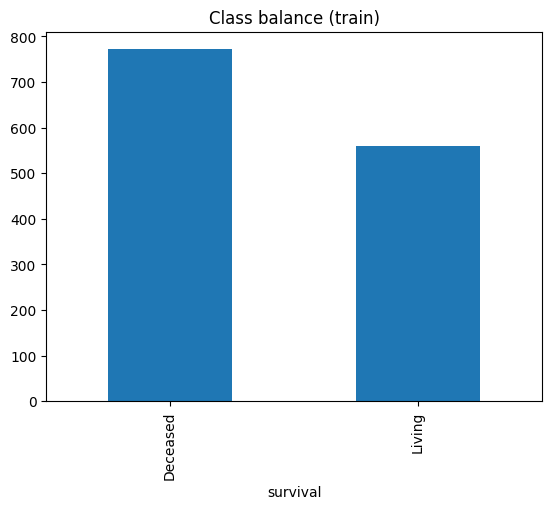

In [38]:
train["survival"].value_counts().plot(kind="bar", title="Class balance (train)")
plt.show()

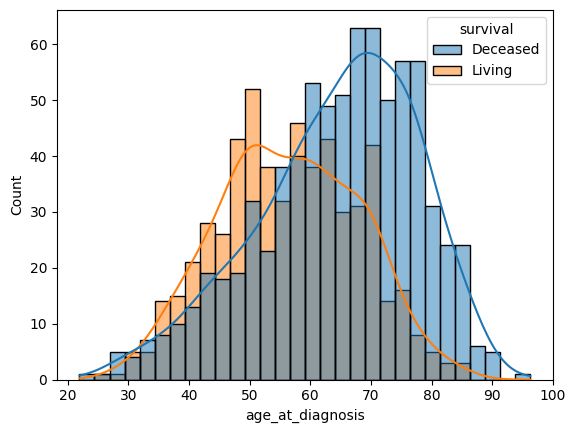

In [39]:
sns.histplot(data=train, x="age_at_diagnosis", hue="survival", kde=True, bins=30)
plt.show()

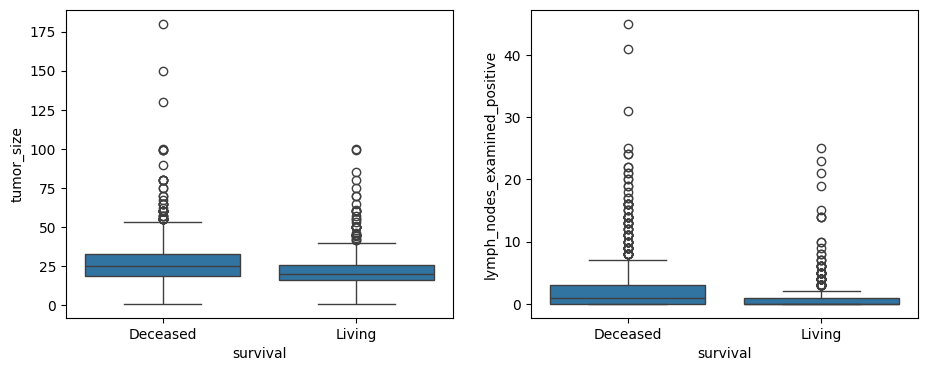

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=train, x="survival", y="tumor_size", ax=ax[0])
sns.boxplot(data=train, x="survival", y="lymph_nodes_examined_positive", ax=ax[1])
plt.show()

In [41]:
for col in ["er_status", "her2_status", "chemotherapy", "tumor_stage"]:
    print(train.groupby(col)["survival"].apply(lambda s: (s == "Living").mean()).round(2), "\n")

er_status
Negative    0.44
Positive    0.41
Name: survival, dtype: float64 

her2_status
Negative    0.43
Positive    0.36
Name: survival, dtype: float64 

chemotherapy
0    0.41
1    0.48
Name: survival, dtype: float64 

tumor_stage
0.0    0.50
1.0    0.55
2.0    0.39
3.0    0.26
4.0    0.11
Name: survival, dtype: float64 



In [42]:
num_train = X_train[num_clin].copy()
num_train["target"] = y_train
print(num_train.corr()["target"].drop("target").sort_values())

age_at_diagnosis                -0.304134
tumor_stage                     -0.191115
lymph_nodes_examined_positive   -0.175968
tumor_size                      -0.171307
nottingham_prognostic_index     -0.151983
neoplasm_histologic_grade       -0.090117
mutation_count                  -0.078506
hormone_therapy                 -0.045233
chemotherapy                     0.058588
radio_therapy                    0.101756
Name: target, dtype: float64


In [43]:
print((X_train[num_clin + cat_clin].isnull().mean() * 100).round(1).sort_values(ascending=False).head(8))

tumor_stage                  26.1
3-gene_classifier_subtype    10.7
primary_tumor_laterality      5.1
neoplasm_histologic_grade     3.6
cellularity                   2.4
mutation_count                2.3
er_status_measured_by_ihc     1.2
tumor_size                    0.9
dtype: float64


In [44]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def dense(a):
    return a.toarray() if hasattr(a, "toarray") else a

Xtr, Xval = dense(Xtr), dense(Xval)
print(Xtr.shape, Xval.shape)          # expect (1332, 748) (286, 748)

results = []   # every experiment gets logged here

def log_result(name, y_true, proba, feature_set, split, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    results.append({
        "model": name, "features": feature_set, "split": split,
        "accuracy": accuracy_score(y_true, pred),
        "precision_deceased": precision_score(y_true, pred, pos_label=0, zero_division=0),
        "recall_deceased": recall_score(y_true, pred, pos_label=0),
        "f1_deceased": f1_score(y_true, pred, pos_label=0),
        "roc_auc": roc_auc_score(y_true, proba),
    })

(1332, 748) (286, 748)


In [45]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
log_result("Baseline (always deceased)", y_val, dummy.predict_proba(Xval)[:, 1], "full", "validation")

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                             eval_metric="logloss", random_state=42),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=42),
}

for name, m in models.items():
    m.fit(Xtr, y_train)                                               # TRAINING
    log_result(name, y_train, m.predict_proba(Xtr)[:, 1], "full", "train")
    log_result(name, y_val,   m.predict_proba(Xval)[:, 1], "full", "validation")
    print("done:", name)

res = pd.DataFrame(results).round(3)
res[res.split == "validation"].sort_values("roc_auc", ascending=False)

done: Logistic Regression
done: Random Forest
done: XGBoost
done: SVM (RBF)


,model,features,split,accuracy,precision_deceased,recall_deceased,f1_deceased,roc_auc
6,XGBoost,full,validation,0.717,0.741,0.782,0.761,0.771
8,SVM (RBF),full,validation,0.710,0.728,0.794,0.759,0.765
4,Random Forest,full,validation,0.717,0.702,0.885,0.783,0.738
2,Logistic Regression,full,validation,0.629,0.690,0.648,0.669,0.693
0,Baseline (always deceased),full,validation,0.577,0.577,1.000,0.732,0.500


In [46]:
res.pivot_table(index=["model", "features"], columns="split", values="roc_auc").round(3)

,split,train,validation
model,features,,
Baseline (always deceased),full,NaN,0.500
Logistic Regression,full,0.997,0.693
Random Forest,full,1.000,0.738
SVM (RBF),full,0.987,0.765
XGBoost,full,1.000,0.771


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

derived = ["pam50_+_claudin-low_subtype", "integrative_cluster", "3-gene_classifier_subtype"]
web_num = [c for c in num_clin if c != "mutation_count"]
web_cat = [c for c in cat_clin if c not in derived]
web_features = web_num + web_cat
print(len(web_num), len(web_cat), web_features)

preprocessor_web = ColumnTransformer([
    ("num", num_pipe, web_num),
    ("cat", cat_pipe, web_cat),
], sparse_threshold=0)

preprocessor_web.fit(X_train[web_features])          # fitted on TRAIN only
Xtr_w  = dense(preprocessor_web.transform(X_train[web_features]))
Xval_w = dense(preprocessor_web.transform(X_val[web_features]))
print(Xtr_w.shape, Xval_w.shape)

models_web = {}
for name, m in models.items():
    mw = clone(m).fit(Xtr_w, y_train)
    models_web[name] = mw
    log_result(name, y_train, mw.predict_proba(Xtr_w)[:, 1], "web (clinical only)", "train")
    log_result(name, y_val,   mw.predict_proba(Xval_w)[:, 1], "web (clinical only)", "validation")

res = pd.DataFrame(results).round(3)
res[res.split == "validation"].sort_values(["features", "roc_auc"], ascending=[True, False])

9 13 ['age_at_diagnosis', 'chemotherapy', 'neoplasm_histologic_grade', 'hormone_therapy', 'lymph_nodes_examined_positive', 'nottingham_prognostic_index', 'radio_therapy', 'tumor_size', 'tumor_stage', 'type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'inferred_menopausal_state', 'primary_tumor_laterality', 'oncotree_code', 'pr_status']
(1332, 61) (286, 61)


,model,features,split,accuracy,precision_deceased,recall_deceased,f1_deceased,roc_auc
6,XGBoost,full,validation,0.717,0.741,0.782,0.761,0.771
8,SVM (RBF),full,validation,0.710,0.728,0.794,0.759,0.765
4,Random Forest,full,validation,0.717,0.702,0.885,0.783,0.738
2,Logistic Regression,full,validation,0.629,0.690,0.648,0.669,0.693
0,Baseline (always deceased),full,validation,0.577,0.577,1.000,0.732,0.500
14,XGBoost,web (clinical only),validation,0.689,0.721,0.752,0.736,0.748
16,SVM (RBF),web (clinical only),validation,0.675,0.696,0.776,0.734,0.745
10,Logistic Regression,web (clinical only),validation,0.706,0.737,0.764,0.750,0.742
12,Random Forest,web (clinical only),validation,0.699,0.718,0.788,0.751,0.740


In [48]:
res.to_csv(f"{BASE}/results/validation_results_day1.csv", index=False)

In [49]:
import tensorflow as tf
from tensorflow import keras

def build_nn(input_dim, lr=0.001, dropout=0.3):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

def train_nn(m, Xa, ya, Xb, yb, epochs=100, batch_size=32):
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                       restore_best_weights=True)
    return m.fit(Xa.astype("float32"), ya.values,
                 validation_data=(Xb.astype("float32"), yb.values),
                 epochs=epochs, batch_size=batch_size, callbacks=[es], verbose=0)

def plot_history(h):
    plt.plot(h.history["loss"], label="train loss")
    plt.plot(h.history["val_loss"], label="validation loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

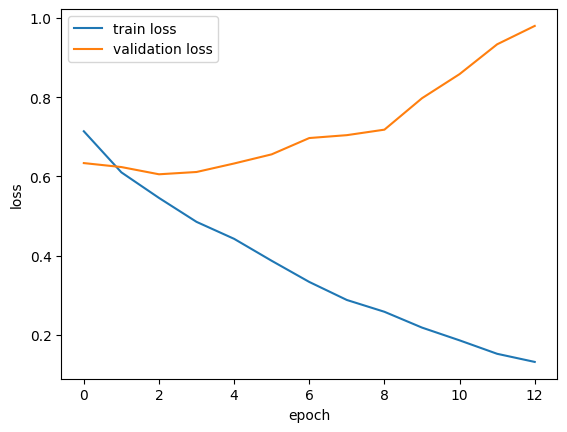

stopped after 13 epochs


In [50]:
nn = build_nn(Xtr.shape[1])
h = train_nn(nn, Xtr, y_train, Xval, y_val)
plot_history(h)
print("stopped after", len(h.history["loss"]), "epochs")

log_result("Neural network", y_train, nn.predict(Xtr.astype("float32"), verbose=0).ravel(), "full", "train")
log_result("Neural network", y_val,   nn.predict(Xval.astype("float32"), verbose=0).ravel(), "full", "validation")

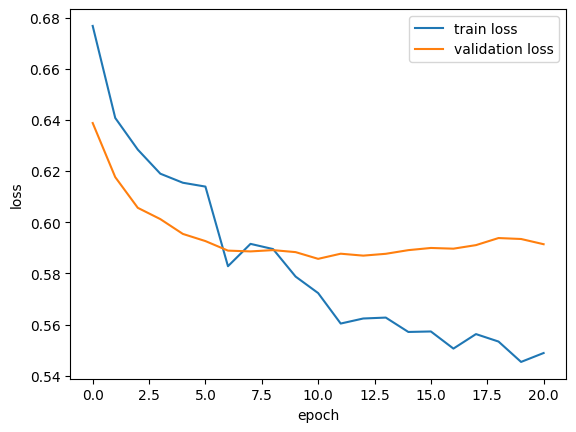

In [51]:
nn_w = build_nn(Xtr_w.shape[1])
h_w = train_nn(nn_w, Xtr_w, y_train, Xval_w, y_val)
plot_history(h_w)
log_result("Neural network", y_train, nn_w.predict(Xtr_w.astype("float32"), verbose=0).ravel(), "web (clinical only)", "train")
log_result("Neural network", y_val,   nn_w.predict(Xval_w.astype("float32"), verbose=0).ravel(), "web (clinical only)", "validation")

In [52]:
for lr in [0.1, 0.001, 0.00001]:
    m = build_nn(Xtr.shape[1], lr=lr)
    hh = train_nn(m, Xtr, y_train, Xval, y_val, epochs=60)
    print(f"lr={lr}: best val loss = {min(hh.history['val_loss']):.3f}, epochs run = {len(hh.history['loss'])}")

lr=0.1: best val loss = 0.681, epochs run = 20
lr=0.001: best val loss = 0.605, epochs run = 13
lr=1e-05: best val loss = 0.647, epochs run = 60


In [53]:
res = pd.DataFrame(results).round(3)
res.to_csv(f"{BASE}/results/validation_results_day2.csv", index=False)
res[res.split == "validation"].sort_values(["features", "roc_auc"], ascending=[True, False])

,model,features,split,accuracy,precision_deceased,recall_deceased,f1_deceased,roc_auc
6,XGBoost,full,validation,0.717,0.741,0.782,0.761,0.771
8,SVM (RBF),full,validation,0.710,0.728,0.794,0.759,0.765
4,Random Forest,full,validation,0.717,0.702,0.885,0.783,0.738
18,Neural network,full,validation,0.647,0.682,0.727,0.704,0.719
2,Logistic Regression,full,validation,0.629,0.690,0.648,0.669,0.693
0,Baseline (always deceased),full,validation,0.577,0.577,1.000,0.732,0.500
20,Neural network,web (clinical only),validation,0.678,0.702,0.770,0.734,0.754
14,XGBoost,web (clinical only),validation,0.689,0.721,0.752,0.736,0.748
16,SVM (RBF),web (clinical only),validation,0.675,0.696,0.776,0.734,0.745
10,Logistic Regression,web (clinical only),validation,0.706,0.737,0.764,0.750,0.742


In [54]:
best = models["XGBoost"]          # change to your best, e.g. models["Random Forest"]

In [55]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)

rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", clone(preprocessor_web)), ("model", clone(m))])
    scores = cross_val_score(pipe, X_train[web_features], y_train,
                             cv=cv, scoring="roc_auc", n_jobs=-1)
    rows.append({"model": name, "mean_auc": scores.mean(), "std": scores.std()})
    print("done:", name)

cv_table = pd.DataFrame(rows).sort_values("mean_auc", ascending=False).round(3)
cv_table

done: Logistic Regression
done: Random Forest
done: XGBoost
done: SVM (RBF)


,model,mean_auc,std
0,Logistic Regression,0.730,0.028
2,XGBoost,0.729,0.024
3,SVM (RBF),0.729,0.039
1,Random Forest,0.716,0.033


In [56]:
res = pd.DataFrame(results).round(3)
res.pivot_table(index=["features", "model"], columns="split", values="roc_auc").round(3)

split                                           train  validation
features            model                                        
full                Baseline (always deceased)    NaN       0.500
                    Logistic Regression         0.997       0.693
                    Neural network              0.911       0.719
                    Random Forest               1.000       0.738
                    SVM (RBF)                   0.987       0.765
                    XGBoost                     1.000       0.771
web (clinical only) Logistic Regression         0.762       0.742
                    Neural network              0.791       0.754
                    Random Forest               1.000       0.740
                    SVM (RBF)                   0.834       0.745
                    XGBoost                     0.882       0.748

In [57]:
rows = []
for name in ["Logistic Regression", "XGBoost", "SVM (RBF)"]:
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", clone(models[name]))])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    rows.append({"model": name, "mean_auc": scores.mean(), "std": scores.std()})
    print("done:", name)
pd.DataFrame(rows).sort_values("mean_auc", ascending=False).round(3)

done: Logistic Regression
done: XGBoost
done: SVM (RBF)


,model,mean_auc,std
2,SVM (RBF),0.747,0.041
1,XGBoost,0.741,0.037
0,Logistic Regression,0.669,0.026


In [58]:
best_w = models_web["XGBoost"]    # untuned web model; swap in the tuned one after Step 10

def predict_p(d):
    """raw patient rows -> P(living)"""
    return best_w.predict_proba(dense(preprocessor_web.transform(d[web_features])))[:, 1]

p_val = predict_p(X_val)
pred_val = (p_val >= 0.5).astype(int)

In [59]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_lr = Pipeline([("prep", clone(preprocessor_web)),
                    ("model", LogisticRegression(max_iter=5000, random_state=42))])

grid_lr = GridSearchCV(pipe_lr,
                       {"model__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]},
                       cv=cv5, scoring="roc_auc", n_jobs=-1, return_train_score=True)
grid_lr.fit(X_train[web_features], y_train)

print("best:", grid_lr.best_params_, "CV AUC:", round(grid_lr.best_score_, 3))
pd.DataFrame(grid_lr.cv_results_)[["param_model__C", "mean_train_score",
                                    "mean_test_score", "std_test_score"]].round(3)

best: {'model__C': 0.03} CV AUC: 0.731


,param_model__C,mean_train_score,mean_test_score,std_test_score
0,0.000,0.727,0.719,0.036
1,0.001,0.731,0.721,0.036
2,0.003,0.739,0.725,0.036
3,0.010,0.748,0.729,0.036
4,0.030,0.755,0.731,0.034
5,0.100,0.761,0.731,0.032
6,0.300,0.763,0.729,0.030
7,1.000,0.765,0.729,0.028


In [60]:
param_xgb = {
    "model__n_estimators":     [100, 200, 300, 500],
    "model__learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "model__max_depth":        [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample":        [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.5, 0.8, 1.0],
    "model__reg_lambda":       [1, 5, 10],
}
pipe_xgb = Pipeline([("prep", clone(preprocessor_web)),
                     ("model", XGBClassifier(eval_metric="logloss", random_state=42))])

rs_xgb = RandomizedSearchCV(pipe_xgb, param_xgb, n_iter=40, cv=cv5,
                            scoring="roc_auc", n_jobs=-1, random_state=42,
                            return_train_score=True)
rs_xgb.fit(X_train[web_features], y_train)

print("best:", rs_xgb.best_params_, "CV AUC:", round(rs_xgb.best_score_, 3))
r = pd.DataFrame(rs_xgb.cv_results_).sort_values("mean_test_score", ascending=False)
r[["mean_train_score", "mean_test_score", "std_test_score", "param_model__max_depth",
   "param_model__learning_rate", "param_model__n_estimators"]].head(5).round(3)

best: {'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 200, 'model__min_child_weight': 10, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0} CV AUC: 0.746


,mean_train_score,mean_test_score,std_test_score,param_model__max_depth,param_model__learning_rate,param_model__n_estimators
6,0.872,0.746,0.033,5,0.03,200
27,0.868,0.745,0.033,5,0.03,100
22,0.810,0.744,0.029,2,0.03,300
30,0.810,0.744,0.033,3,0.01,300
5,0.875,0.743,0.029,3,0.03,500


In [61]:
for name, est in [("Logistic Regression (tuned)", grid_lr.best_estimator_),
                  ("XGBoost (tuned)", rs_xgb.best_estimator_)]:
    log_result(name, y_train, est.predict_proba(X_train[web_features])[:, 1], "web (clinical only)", "train")
    log_result(name, y_val,   est.predict_proba(X_val[web_features])[:, 1],   "web (clinical only)", "validation")

res = pd.DataFrame(results).round(3)
cols = ["model", "accuracy", "precision_deceased", "recall_deceased", "f1_deceased", "roc_auc"]
res[(res.split == "validation") & (res.features == "web (clinical only)")] \
    .sort_values("roc_auc", ascending=False)[cols]

,model,accuracy,precision_deceased,recall_deceased,f1_deceased,roc_auc
20,Neural network,0.678,0.702,0.770,0.734,0.754
22,Logistic Regression (tuned),0.703,0.720,0.794,0.755,0.749
14,XGBoost,0.689,0.721,0.752,0.736,0.748
16,SVM (RBF),0.675,0.696,0.776,0.734,0.745
24,XGBoost (tuned),0.682,0.710,0.758,0.733,0.744
10,Logistic Regression,0.706,0.737,0.764,0.750,0.742
12,Random Forest,0.699,0.718,0.788,0.751,0.740


In [62]:
def build_nn2(input_dim, units, dropout, lr):
    keras.utils.set_random_seed(42)
    layers = [keras.layers.Input(shape=(input_dim,))]
    for u in units:
        layers += [keras.layers.Dense(u, activation="relu"), keras.layers.Dropout(dropout)]
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    m = keras.Sequential(layers)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy")
    return m

configs = [
    dict(units=(64, 32),  dropout=0.3, lr=1e-3, batch=32),
    dict(units=(32,),     dropout=0.3, lr=1e-3, batch=32),
    dict(units=(128, 64), dropout=0.5, lr=1e-3, batch=32),
    dict(units=(64, 32),  dropout=0.3, lr=1e-3, batch=64),
    dict(units=(64, 32),  dropout=0.3, lr=3e-4, batch=32),
]
rows = []
for c in configs:
    m = build_nn2(Xtr_w.shape[1], c["units"], c["dropout"], c["lr"])
    h = train_nn(m, Xtr_w, y_train, Xval_w, y_val, batch_size=c["batch"])
    auc = roc_auc_score(y_val, m.predict(Xval_w.astype("float32"), verbose=0).ravel())
    rows.append({**c, "epochs": len(h.history["loss"]), "val_auc": round(auc, 3)})
pd.DataFrame(rows)

,units,dropout,lr,batch,epochs,val_auc
0,"(64, 32)",0.3,0.0010,32,21,0.754
1,"(32,)",0.3,0.0010,32,26,0.760
2,"(128, 64)",0.5,0.0010,32,27,0.763
3,"(64, 32)",0.3,0.0010,64,33,0.759
4,"(64, 32)",0.3,0.0003,32,41,0.758


In [63]:
rng = np.random.default_rng(42)
pick = rng.choice(len(y_val), size=8, replace=False)

table = pd.DataFrame({
    "patient_id": df["patient_id"].iloc[idx_val].values[pick],
    "age": X_val["age_at_diagnosis"].values[pick].round(1),
    "tumor_size": X_val["tumor_size"].values[pick],
    "true": y_val.values[pick],
    "pred": pred_val[pick],
    "P(living)": p_val[pick].round(2),
})
table["correct"] = table["true"] == table["pred"]
table

,patient_id,age,tumor_size,true,pred,P(living),correct
0,5013,68.6,20.0,0,0,0.38,True
1,316,50.8,30.0,1,1,0.72,True
2,880,73.6,30.0,1,0,0.22,False
3,3452,64.0,30.0,0,0,0.35,True
4,3110,61.1,16.0,1,1,0.52,True
5,5346,52.1,80.0,1,0,0.36,False
6,4222,58.8,40.0,0,0,0.39,True
7,5124,84.0,26.0,0,0,0.16,True


In [64]:
row = X_val.iloc[[0]].copy()
for age in [35, 55, 80]:
    r = row.copy()
    r["age_at_diagnosis"] = age
    print(f"age {age}: P(living) = {predict_p(r)[0]:.2f}")

age 35: P(living) = 0.77
age 55: P(living) = 0.68
age 80: P(living) = 0.15


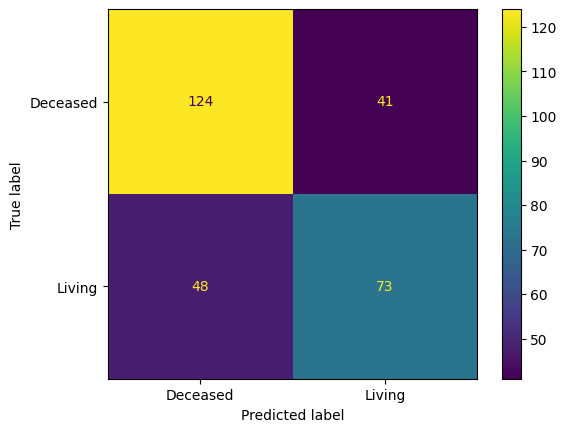

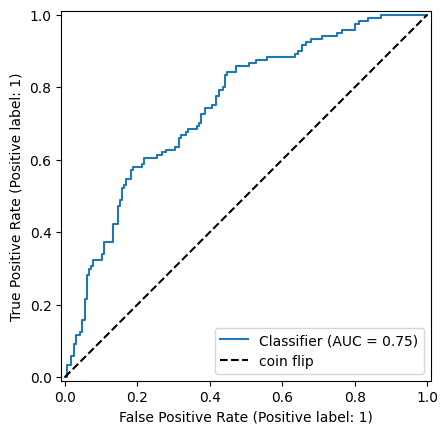

              precision    recall  f1-score   support

    Deceased       0.72      0.75      0.74       165
      Living       0.64      0.60      0.62       121

    accuracy                           0.69       286
   macro avg       0.68      0.68      0.68       286
weighted avg       0.69      0.69      0.69       286

ROC-AUC: 0.748


In [65]:
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report, roc_auc_score)

ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Deceased", "Living"])
plt.show()

RocCurveDisplay.from_predictions(y_val, p_val)
plt.plot([0, 1], [0, 1], "k--", label="coin flip"); plt.legend(); plt.show()

print(classification_report(y_val, pred_val, target_names=["Deceased", "Living"]))
print("ROC-AUC:", round(roc_auc_score(y_val, p_val), 3))

In [66]:
errors = X_val.copy()
errors["true"] = y_val.values
errors["wrong"] = (pred_val != y_val.values)

print(errors.groupby("wrong")[["age_at_diagnosis", "tumor_size", "lymph_nodes_examined_positive"]].mean().round(1))
print(pd.crosstab(errors["er_status"], errors["wrong"], normalize="index").round(2))

       age_at_diagnosis  tumor_size  lymph_nodes_examined_positive
wrong                                                             
False              61.7        27.0                            2.2
True               58.5        27.4                            1.6
wrong      False  True 
er_status              
Negative    0.70   0.30
Positive    0.69   0.31


In [67]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pr = (p_val >= t).astype(int)
    rows.append({"threshold": t,
                 "recall_deceased": recall_score(y_val, pr, pos_label=0),
                 "precision_deceased": precision_score(y_val, pr, pos_label=0, zero_division=0)})
pd.DataFrame(rows).round(3)

,threshold,recall_deceased,precision_deceased
0,0.3,0.467,0.837
1,0.4,0.612,0.754
2,0.5,0.752,0.721
3,0.6,0.855,0.681
4,0.7,0.933,0.644


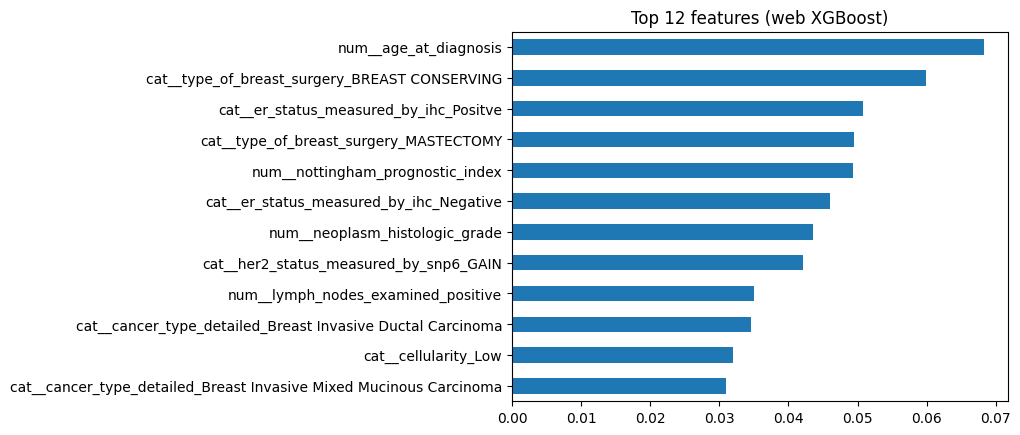

In [68]:
names = preprocessor_web.get_feature_names_out()
imp = pd.Series(models_web["XGBoost"].feature_importances_, index=names).sort_values(ascending=False).head(12)
imp.plot(kind="barh", title="Top 12 features (web XGBoost)")
plt.gca().invert_yaxis(); plt.show()

In [69]:
errors["type"] = np.select(
    [(errors["true"] == 0) & (pred_val == 1), (errors["true"] == 1) & (pred_val == 0)],
    ["False negative (died, predicted living)", "False alarm (lived, predicted deceased)"],
    default="Correct")
print(errors["type"].value_counts())
print(errors.groupby("type")[["age_at_diagnosis", "tumor_size", "lymph_nodes_examined_positive"]].mean().round(1))

type
Correct                                    197
False alarm (lived, predicted deceased)     48
False negative (died, predicted living)     41
Name: count, dtype: int64
                                         age_at_diagnosis  tumor_size  \
type                                                                    
Correct                                              61.7        27.0   
False alarm (lived, predicted deceased)              62.2        32.4   
False negative (died, predicted living)              54.3        21.4   

                                         lymph_nodes_examined_positive  
type                                                                    
Correct                                                            2.2  
False alarm (lived, predicted deceased)                            2.2  
False negative (died, predicted living)                            0.9  


In [70]:
import joblib, json

treat = ["chemotherapy", "hormone_therapy", "radio_therapy", "type_of_breast_surgery"]
spw = (y_train == 0).sum() / (y_train == 1).sum()      # about 1.38, up-weights the living class

def make_prep(num_cols, cat_cols):
    return ColumnTransformer([("num", num_pipe, num_cols),
                              ("cat", cat_pipe, cat_cols)], sparse_threshold=0)

def run_exp(label, pipe, feats, Xa, ya, Xb, yb):
    cvs = cross_val_score(pipe, Xa[feats], ya, cv=cv5, scoring="roc_auc", n_jobs=-1)  # train data only
    pipe.fit(Xa[feats], ya)
    pv = pipe.predict_proba(Xb[feats])[:, 1]                                          # validation
    log_result(label, yb, pv, "web (clinical only)", "validation")
    return {"experiment": label,
            "cv_auc": round(cvs.mean(), 3), "cv_std": round(cvs.std(), 3),
            "val_auc": round(roc_auc_score(yb, pv), 3),
            "val_recall_deceased": round(recall_score(yb, (pv >= 0.5).astype(int), pos_label=0), 3)}

rows = []

In [71]:
args = (web_features, X_train, y_train, X_val, y_val)
rows.append(run_exp("LR tuned (reference)", clone(grid_lr.best_estimator_), *args))
rows.append(run_exp("LR + class_weight",
            clone(grid_lr.best_estimator_).set_params(model__class_weight="balanced"), *args))
rows.append(run_exp("XGB tuned (reference)", clone(rs_xgb.best_estimator_), *args))
rows.append(run_exp("XGB + scale_pos_weight",
            clone(rs_xgb.best_estimator_).set_params(model__scale_pos_weight=spw), *args))
pd.DataFrame(rows)

,experiment,cv_auc,cv_std,val_auc,val_recall_deceased
0,LR tuned (reference),0.731,0.034,0.749,0.794
1,LR + class_weight,0.731,0.034,0.750,0.655
2,XGB tuned (reference),0.746,0.033,0.744,0.758
3,XGB + scale_pos_weight,0.746,0.032,0.748,0.661


In [72]:
nt_num = [c for c in web_num if c not in treat]
nt_cat = [c for c in web_cat if c not in treat]
nt_features = nt_num + nt_cat
print(len(web_features), "->", len(nt_features))

pipe_nt = Pipeline([("prep", make_prep(nt_num, nt_cat)),
                    ("model", clone(grid_lr.best_estimator_.named_steps["model"]))])
rows.append(run_exp("LR, no treatment columns", pipe_nt, nt_features,
                    X_train, y_train, X_val, y_val))
pd.DataFrame(rows)

22 -> 18


,experiment,cv_auc,cv_std,val_auc,val_recall_deceased
0,LR tuned (reference),0.731,0.034,0.749,0.794
1,LR + class_weight,0.731,0.034,0.750,0.655
2,XGB tuned (reference),0.746,0.033,0.744,0.758
3,XGB + scale_pos_weight,0.746,0.032,0.748,0.661
4,"LR, no treatment columns",0.719,0.033,0.733,0.794


In [73]:
dfc = df["death_from_cancer"]
kt = dfc.loc[X_train.index].isin(["Living", "Died of Disease"]).values
kv = dfc.loc[X_val.index].isin(["Living", "Died of Disease"]).values

Xtr_c, ytr_c = X_train[kt], y_train[kt]
Xv_c,  yv_c  = X_val[kv],  y_val[kv]
print(len(ytr_c), len(yv_c), "living share (train):", round(ytr_c.mean(), 3))

rows.append(run_exp("LR, cancer-deaths-only target", clone(grid_lr.best_estimator_),
                    web_features, Xtr_c, ytr_c, Xv_c, yv_c))
pd.DataFrame(rows)

1002 210 living share (train): 0.559


,experiment,cv_auc,cv_std,val_auc,val_recall_deceased
0,LR tuned (reference),0.731,0.034,0.749,0.794
1,LR + class_weight,0.731,0.034,0.750,0.655
2,XGB tuned (reference),0.746,0.033,0.744,0.758
3,XGB + scale_pos_weight,0.746,0.032,0.748,0.661
4,"LR, no treatment columns",0.719,0.033,0.733,0.794
5,"LR, cancer-deaths-only target",0.720,0.034,0.739,0.539


In [74]:
# Option A (reference):
final_name  = "Logistic Regression (tuned)"
final_feats = web_features
final_pipe  = clone(grid_lr.best_estimator_)

# Option B (class weights):
# final_name  = "Logistic Regression + class weights"
# final_feats = web_features
# final_pipe  = clone(grid_lr.best_estimator_).set_params(model__class_weight="balanced")

# Option C (no treatment columns):
# final_name  = "Logistic Regression (no treatment inputs)"
# final_feats = nt_features
# final_pipe  = clone(pipe_nt)

print("FINAL MODEL:", final_name, "| inputs:", len(final_feats))

FINAL MODEL: Logistic Regression (tuned) | inputs: 22


In [75]:
final_pipe.fit(X_train[final_feats], y_train)
p_test = final_pipe.predict_proba(X_test[final_feats])[:, 1]
pred_test = (p_test >= 0.5).astype(int)
log_result(final_name, y_test, p_test, "web (clinical only)", "TEST")

              precision    recall  f1-score   support

    Deceased       0.68      0.78      0.72       166
      Living       0.61      0.48      0.54       120

    accuracy                           0.65       286
   macro avg       0.64      0.63      0.63       286
weighted avg       0.65      0.65      0.65       286

Test ROC-AUC: 0.704
Baseline accuracy (always deceased): 0.58


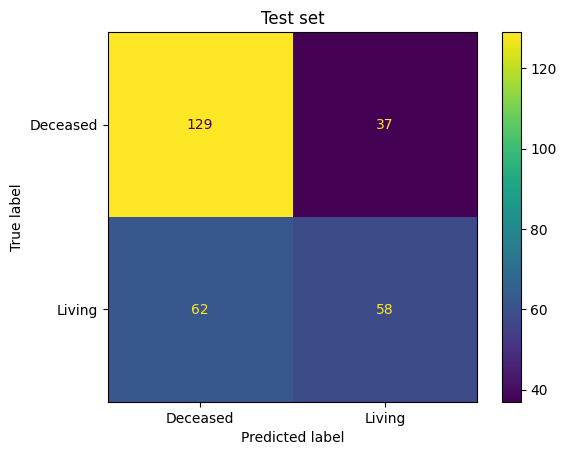

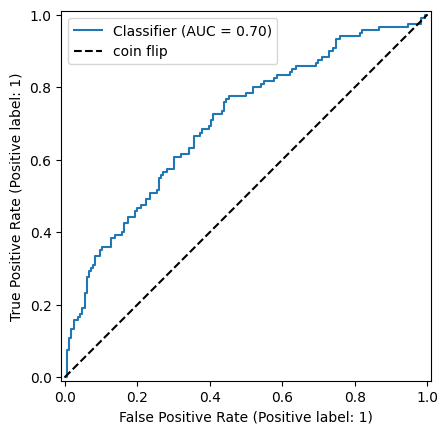

In [76]:
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

print(classification_report(y_test, pred_test, target_names=["Deceased", "Living"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, p_test), 3))
print("Baseline accuracy (always deceased):", round((y_test == 0).mean(), 3))

ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Deceased", "Living"])
plt.title("Test set"); plt.show()
RocCurveDisplay.from_predictions(y_test, p_test)
plt.plot([0, 1], [0, 1], "k--", label="coin flip"); plt.legend(); plt.show()

In [77]:
rng = np.random.default_rng(42)
yt = y_test.values
aucs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[i])) == 2:
        aucs.append(roc_auc_score(yt[i], p_test[i]))
print("95% interval for AUC:", np.percentile(aucs, [2.5, 97.5]).round(3))

95% interval for AUC: [0.632 0.765]


In [78]:
pick = np.random.default_rng(7).choice(len(y_test), size=6, replace=False)
tt = pd.DataFrame({
    "patient_id": df["patient_id"].iloc[idx_test].values[pick],
    "age": X_test["age_at_diagnosis"].values[pick].round(1),
    "true": y_test.values[pick],
    "pred": pred_test[pick],
    "P(living)": p_test[pick].round(2)})
tt["correct"] = tt["true"] == tt["pred"]
tt

,patient_id,age,true,pred,P(living),correct
0,449,54.4,1,1,0.66,True
1,172,48.1,1,1,0.70,True
2,7174,60.6,1,1,0.65,True
3,6179,59.1,0,0,0.47,True
4,4348,61.6,0,0,0.21,True
5,7007,54.4,1,0,0.47,False


In [80]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=tt)

https://docs.google.com/spreadsheets/d/14_3PUcTsOEQ5u3x4ZLVh5KyfCdRQm245esseAkfVOwk/edit#gid=0


In [81]:
X_tv = pd.concat([X_train, X_val])
y_tv = pd.concat([y_train, y_val])

deploy_pipe = clone(final_pipe).fit(X_tv[final_feats], y_tv)

os.makedirs(f"{BASE}/models", exist_ok=True)
joblib.dump(deploy_pipe, f"{BASE}/models/metabric_final_pipeline.joblib")
with open(f"{BASE}/models/metabric_final_features.json", "w") as f:
    json.dump({"model": final_name, "features": final_feats}, f)

# quick reload check, imitating what the backend will do
loaded = joblib.load(f"{BASE}/models/metabric_final_pipeline.joblib")
print(loaded.predict_proba(X_test[final_feats].iloc[:3])[:, 1].round(2))

[0.39 0.55 0.33]


In [82]:
pd.DataFrame(rows).to_csv(f"{BASE}/results/step11_experiments.csv", index=False)
pd.DataFrame(results).round(3).to_csv(f"{BASE}/results/all_results_metabric.csv", index=False)

In [83]:
rng = np.random.default_rng(42)
yt = y_test.values
aucs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[i])) == 2:
        aucs.append(roc_auc_score(yt[i], p_test[i]))
print("95% interval for AUC:", np.percentile(aucs, [2.5, 97.5]).round(3))

95% interval for AUC: [0.632 0.765]


In [84]:
print(classification_report(y_test, pred_test, target_names=["Deceased", "Living"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, p_test), 3))
print("Baseline accuracy:", round((y_test == 0).mean(), 3))

              precision    recall  f1-score   support

    Deceased       0.68      0.78      0.72       166
      Living       0.61      0.48      0.54       120

    accuracy                           0.65       286
   macro avg       0.64      0.63      0.63       286
weighted avg       0.65      0.65      0.65       286

Test ROC-AUC: 0.704
Baseline accuracy: 0.58


In [85]:
X_tv = pd.concat([X_train, X_val])
y_tv = pd.concat([y_train, y_val])

deploy_pipe = clone(final_pipe).fit(X_tv[final_feats], y_tv)

os.makedirs(f"{BASE}/models", exist_ok=True)
joblib.dump(deploy_pipe, f"{BASE}/models/metabric_final_pipeline.joblib")
with open(f"{BASE}/models/metabric_final_features.json", "w") as f:
    json.dump({"model": final_name, "features": final_feats}, f)

loaded = joblib.load(f"{BASE}/models/metabric_final_pipeline.joblib")
print(loaded.predict_proba(X_test[final_feats].iloc[:3])[:, 1].round(2))

[0.39 0.55 0.33]


In [86]:
pd.DataFrame(rows).to_csv(f"{BASE}/results/step11_experiments.csv", index=False)
pd.DataFrame(results).round(3).to_csv(f"{BASE}/results/all_results_metabric.csv", index=False)

In [87]:
X_tv = pd.concat([X_train, X_val])
y_tv = pd.concat([y_train, y_val])

deploy_pipe = clone(final_pipe).fit(X_tv[final_feats], y_tv)

os.makedirs(f"{BASE}/models", exist_ok=True)
joblib.dump(deploy_pipe, f"{BASE}/models/metabric_final_pipeline.joblib")
with open(f"{BASE}/models/metabric_final_features.json", "w") as f:
    json.dump({"model": final_name, "features": final_feats}, f)

# quick reload check, imitating what the backend will do
loaded = joblib.load(f"{BASE}/models/metabric_final_pipeline.joblib")
print(loaded.predict_proba(X_test[final_feats].iloc[:3])[:, 1].round(2))

[0.39 0.55 0.33]


# Phase 2

In [88]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/breast-cancer-project/breakhis"
for sub in ["data/raw", "data/processed", "models", "results"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data', 'models', 'results', 'deploy', 'proj_backup']


In [89]:
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [90]:
!kaggle datasets download -d ambarish/breakhis -p /content/breakhis_zip
!ls -lh /content/breakhis_zip

Dataset URL: https://www.kaggle.com/datasets/ambarish/breakhis
License(s): unknown
100% 3.99G/3.99G [00:49<00:00, 85.7MB/s]

total 4.0G
-rw-r--r-- 1 root root 4.0G Mar 10  2020 breakhis.zip


In [91]:
!unzip -q /content/breakhis_zip/breakhis.zip -d "{BASE}/data/raw"

replace /content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/README.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
RAW = f"{BASE}/data/raw"
for root, dirs, files in os.walk(RAW):
    depth = root.replace(RAW, "").count(os.sep)
    if depth <= 2:
        print(root.replace(RAW, "") or "/", "| subfolders:", len(dirs), "| files:", len(files))

/ | subfolders: 1 | files: 1
/BreaKHis_v1 | subfolders: 1 | files: 0
/BreaKHis_v1/BreaKHis_v1 | subfolders: 1 | files: 0


In [ ]:
import glob
pngs = glob.glob(f"{RAW}/**/*.png", recursive=True)
print("PNG count:", len(pngs))
print("\n".join(pngs[:5]))

In [ ]:
import pandas as pd
folds = glob.glob(f"{RAW}/**/Folds.csv", recursive=True)
print(folds)
f = pd.read_csv(folds[0])
print(f.shape)
f.head()

In [ ]:
import pandas as pd, os

rows = []
for path in pngs:
    name = os.path.basename(path).replace(".png", "")
    parts = name.split("-")                    # ['SOB_B_TA','14','4659','40','001']
    biopsy, cls, subtype = parts[0].split("_")
    rows.append({
        "path": path,
        "class": cls,                          # B or M
        "label": 1 if cls == "M" else 0,       # malignant = 1
        "subtype": subtype,
        "patient_id": f"{parts[1]}-{parts[2]}",
        "magnification": int(parts[3]),
        "img_no": parts[4],
    })

meta = pd.DataFrame(rows)
print(meta.shape)
meta.head()

In [ ]:
assert meta["path"].is_unique
assert meta["class"].isin(["B", "M"]).all()
assert meta["magnification"].isin([40, 100, 200, 400]).all()
print("Missing values:\n", meta.isna().sum())

In [ ]:
print("Images per class:\n", meta["class"].value_counts(), "\n")
print("Images per subtype:\n", meta["subtype"].value_counts(), "\n")
print("Images per magnification:\n", meta["magnification"].value_counts().sort_index(), "\n")
print("Patients:", meta["patient_id"].nunique())
print("Patients per class:\n", meta.groupby("class")["patient_id"].nunique(), "\n")
per_pat = meta.groupby("patient_id").size()
print("Images per patient:\n", per_pat.describe())

In [ ]:
print((meta.groupby("patient_id")["class"].nunique() > 1).sum())   # should print 0

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
meta["class"].value_counts().plot.bar(ax=ax[0], title="Images per class")
meta["subtype"].value_counts().plot.bar(ax=ax[1], title="Images per subtype")

per_pat.sort_values().plot.bar(ax=ax[2], title="Images per patient")
ax[2].set_xticklabels([])          # hide the 82 patient IDs
ax[2].set_xlabel("patients (sorted)")

plt.tight_layout(); plt.show()

In [ ]:
from PIL import Image

sample = pd.concat([
    meta[meta["class"] == "B"].sample(4, random_state=42),
    meta[meta["class"] == "M"].sample(4, random_state=42),
])
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r["path"]))
    ax.set_title(f'{r["class"]} {r["subtype"]} {r["magnification"]}X')
    ax.axis("off")
plt.tight_layout(); plt.show()
print(Image.open(sample.iloc[0]["path"]).size)   # image size in pixels

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import pandas as pd, numpy as np

BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
RAW = f"{BASE_BH}/data/raw"
for sub in ["data/raw", "data/processed", "models", "results"]:
    os.makedirs(f"{BASE_BH}/{sub}", exist_ok=True)

meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv")
print(meta.shape)          # expect (7909, 7)

In [ ]:
import pandas as pd, glob, os

pngs = glob.glob(f"{BASE_BH}/**/*.png", recursive=True)
rows = []
for path in pngs:
    name = os.path.basename(path).replace(".png", "")
    parts = name.split("-")                      # ['SOB_B_TA','14','4659','40','001']
    biopsy, cls, subtype = parts[0].split("_")
    rows.append({"path": path, "class": cls, "label": 1 if cls == "M" else 0,
                 "subtype": subtype, "patient_id": f"{parts[1]}-{parts[2]}",
                 "magnification": int(parts[3]), "img_no": parts[4]})
meta = pd.DataFrame(rows)

assert meta["path"].is_unique
assert meta["class"].isin(["B", "M"]).all()
assert meta["magnification"].isin([40, 100, 200, 400]).all()

meta.to_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv", index=False)
print(meta.shape)                                    # expect (7909, 7)
print(meta["class"].value_counts().to_string())      # expect B 2480, M 5429
print("Patients:", meta["patient_id"].nunique())     # expect 82
print("Patients with two classes:", (meta.groupby("patient_id")["class"].nunique() > 1).sum())  # expect 0
meta.head()

In [ ]:
patients = meta.groupby("patient_id").agg(label=("label", "first"), n_images=("path", "size")).reset_index()
print(patients.shape)                  # (82, 3)
print(patients["label"].value_counts())  # 58 malignant, 24 benign

In [ ]:
from sklearn.model_selection import train_test_split

p_train, p_temp = train_test_split(patients, test_size=0.30, stratify=patients["label"], random_state=42)
p_val, p_test = train_test_split(p_temp, test_size=0.50, stratify=p_temp["label"], random_state=42)

split_map = {pid: "train" for pid in p_train.patient_id}
split_map.update({pid: "val" for pid in p_val.patient_id})
split_map.update({pid: "test" for pid in p_test.patient_id})
meta["split"] = meta["patient_id"].map(split_map)
print(meta["split"].isna().sum())     # must be 0

In [ ]:
ids = {s: set(meta.loc[meta.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (ids["train"] & ids["val"])
assert not (ids["train"] & ids["test"])
assert not (ids["val"] & ids["test"])
print("No patient appears in two sets")

print(meta.groupby("split")["patient_id"].nunique())            # patients per set
print(meta.groupby("split").size())                              # images per set
print(meta.groupby("split")["label"].mean().round(3))            # malignant share (images)
print(meta.groupby(["split", "class"])["patient_id"].nunique())  # patients per class per set

In [ ]:
meta.to_csv(f"{BASE_BH}/data/processed/breakhis_split.csv", index=False)

In [ ]:
from PIL import Image
from tqdm import tqdm

IMG = 224
X = np.zeros((len(meta), IMG, IMG, 3), dtype=np.uint8)
for i, p in enumerate(tqdm(meta["path"].values)):
    X[i] = np.array(Image.open(p).convert("RGB").resize((IMG, IMG)))
y = meta["label"].values.astype("float32")

np.save(f"{BASE_BH}/data/processed/X_224.npy", X)
np.save(f"{BASE_BH}/data/processed/y.npy", y)
print(X.shape, X.dtype)    # (7909, 224, 224, 3) uint8

In [ ]:
tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]      # set aside; not used until the very end
print(X_train.shape, X_val.shape, X_test.shape)

In [ ]:
import tensorflow as tf
from tensorflow import keras

BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

In [ ]:
import matplotlib.pyplot as plt
img = tf.cast(X_train[0:1], tf.float32) / 255.0
fig, axes = plt.subplots(1, 7, figsize=(18, 3))
axes[0].imshow(img[0]); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(img, training=True)[0]); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.show()

In [ ]:
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")
X = np.load(f"{BASE_BH}/data/processed/X_224.npy")
y = np.load(f"{BASE_BH}/data/processed/y.npy")

In [ ]:
print(tf.config.list_physical_devices("GPU"))   # should list one GPU

In [ ]:
n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}
print(class_weight)    # benign weight > 1, malignant weight < 1

In [ ]:
def build_cnn(dropout=0.4):
    m = keras.Sequential([
        keras.layers.Input((224, 224, 3)),
        keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(128, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

keras.utils.set_random_seed(42)
cnn = build_cnn()
cnn.summary()

In [ ]:
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hist = cnn.fit(train_ds, validation_data=val_ds, epochs=30,
               class_weight=class_weight, callbacks=[es])

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val")
ax[1].set_title("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

pv = cnn.predict(val_ds).ravel()
pred = (pv >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

res = {
    "model": "baseline_cnn", "split": "validation",
    "accuracy": accuracy_score(y_val, pred),
    "balanced_acc": balanced_accuracy_score(y_val, pred),
    "precision": precision_score(y_val, pred),
    "recall_malignant": recall_score(y_val, pred),
    "specificity_benign": tn / (tn + fp),
    "f1": f1_score(y_val, pred),
    "auc": roc_auc_score(y_val, pv),
}
print(pd.Series(res).round(3))
print(confusion_matrix(y_val, pred))

In [ ]:
pd.DataFrame([res]).round(3).to_csv(f"{BASE_BH}/results/breakhis_baseline.csv", index=False)
cnn.save(f"{BASE_BH}/models/breakhis_baseline_cnn.keras")

In [ ]:
def build_transfer(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(2.0, offset=-1.0)(inp)     # [0,1] -> [-1,1]
    x = base(x, training=False)                            # keeps BatchNorm in inference mode
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    return m, base

keras.utils.set_random_seed(42)
tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])
tl.summary()

In [ ]:
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
h1 = tl.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

tl.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])   # re-compile after changing trainable

es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
h2 = tl.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])

In [ ]:
import matplotlib.pyplot as plt
loss = h1.history["loss"] + h2.history["loss"];   vloss = h1.history["val_loss"] + h2.history["val_loss"]
auc = h1.history["auc"] + h2.history["auc"];      vauc = h1.history["val_auc"] + h2.history["val_auc"]
k = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, tr, va, t in [(ax[0], loss, vloss, "Loss"), (ax[1], auc, vauc, "AUC")]:
    a.plot(tr, label="train"); a.plot(va, label="val"); a.axvline(k - 0.5, ls="--", c="gray"); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

pv = tl.predict(val_ds).ravel()
pred = (pv >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
res = {"model": "mobilenetv2_finetuned", "split": "validation",
       "accuracy": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
       "precision": precision_score(y_val, pred), "recall_malignant": recall_score(y_val, pred),
       "specificity_benign": tn / (tn + fp), "f1": f1_score(y_val, pred), "auc": roc_auc_score(y_val, pv)}

base_res = pd.read_csv(f"{BASE_BH}/results/breakhis_baseline.csv")
cmp = pd.concat([base_res, pd.DataFrame([res]).round(3)], ignore_index=True)
print(cmp.to_string(index=False))
print(confusion_matrix(y_val, pred))

In [ ]:
cmp.to_csv(f"{BASE_BH}/results/breakhis_val_comparison.csv", index=False)
tl.save(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")

In [ ]:
def build_effnet(dropout=0.3):
    base = keras.applications.EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(255.0)(inp)               # [0,1] -> [0,255]
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out), base

keras.utils.set_random_seed(42)
eff, ebase = build_effnet()
eff.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")])

In [ ]:
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
e1 = eff.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

ebase.trainable = True
for layer in ebase.layers[:-30]:
    layer.trainable = False
for layer in ebase.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
eff.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")])
es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
e2 = eff.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv),
        "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "f1": f1_score(y_val, pred)}

cnn = keras.models.load_model(f"{BASE_BH}/models/breakhis_baseline_cnn.keras")
mob = keras.models.load_model(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")
probs, rows = {}, []
for name, m in [("baseline_cnn", cnn), ("mobilenetv2", mob), ("efficientnetb0", eff)]:
    probs[name], r = score(name, m)
    rows.append(r)
tab = pd.DataFrame(rows).round(3)
tab["gap"] = (tab["train_auc"] - tab["val_auc"]).round(3)
print(tab.to_string(index=False))

In [ ]:
val_meta = meta[meta["split"] == "val"].reset_index(drop=True)
for name, pv in probs.items():
    d = val_meta.assign(p=pv).groupby("patient_id").agg(label=("label", "first"), p=("p", "mean"))
    pat_pred = (d["p"] >= 0.5).astype(int)
    print(name, "| patients:", len(d),
          "| patient accuracy:", round((pat_pred == d["label"]).mean(), 3),
          "| patient AUC:", round(roc_auc_score(d["label"], d["p"]), 3))

In [ ]:
tab.to_csv(f"{BASE_BH}/results/breakhis_val_comparison_all.csv", index=False)
eff.save(f"{BASE_BH}/models/breakhis_efficientnetb0.keras")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np, pandas as pd

BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
for sub in ["data/processed", "models", "results"]:
    os.makedirs(f"{BASE_BH}/{sub}", exist_ok=True)

meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv")
print(meta.shape)     # expect (7909, 7)

In [ ]:
patients = meta.groupby("patient_id").agg(label=("label", "first"), n_images=("path", "size")).reset_index()
print(patients.shape)                    # (82, 3)
print(patients["label"].value_counts())  # 58 malignant, 24 benign

In [ ]:
from sklearn.model_selection import train_test_split

p_train, p_temp = train_test_split(patients, test_size=0.30, stratify=patients["label"], random_state=42)
p_val, p_test = train_test_split(p_temp, test_size=0.50, stratify=p_temp["label"], random_state=42)

split_map = {pid: "train" for pid in p_train.patient_id}
split_map.update({pid: "val" for pid in p_val.patient_id})
split_map.update({pid: "test" for pid in p_test.patient_id})
meta["split"] = meta["patient_id"].map(split_map)
print("Unassigned rows (must be 0):", meta["split"].isna().sum())

In [ ]:
ids = {s: set(meta.loc[meta.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (ids["train"] & ids["val"])
assert not (ids["train"] & ids["test"])
assert not (ids["val"] & ids["test"])
print("No patient appears in two sets\n")
print("Patients per set:\n", meta.groupby("split")["patient_id"].nunique().to_string())
print("\nImages per set:\n", meta.groupby("split").size().to_string())
print("\nMalignant share (images):\n", meta.groupby("split")["label"].mean().round(3).to_string())
print("\nPatients per class per set:\n", meta.groupby(["split", "class"])["patient_id"].nunique().unstack().to_string())

meta.to_csv(f"{BASE_BH}/data/processed/breakhis_split.csv", index=False)

In [ ]:
from PIL import Image
from tqdm import tqdm

IMG = 224
X = np.zeros((len(meta), IMG, IMG, 3), dtype=np.uint8)
for i, p in enumerate(tqdm(meta["path"].values)):
    X[i] = np.array(Image.open(p).convert("RGB").resize((IMG, IMG)))
y = meta["label"].values.astype("float32")

np.save(f"{BASE_BH}/data/processed/X_224.npy", X)
np.save(f"{BASE_BH}/data/processed/y.npy", y)
print(X.shape, X.dtype)       # (7909, 224, 224, 3) uint8

In [ ]:
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")
X = np.load(f"{BASE_BH}/data/processed/X_224.npy")
y = np.load(f"{BASE_BH}/data/processed/y.npy")
print(X.shape, meta.shape)

In [ ]:
tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]        # set aside; not used until the final evaluation
print(X_train.shape, X_val.shape, X_test.shape)

import tensorflow as tf
from tensorflow import keras
print("GPU:", tf.config.list_physical_devices("GPU"))

BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

In [ ]:
import matplotlib.pyplot as plt
img = tf.cast(X_train[0:1], tf.float32) / 255.0
fig, axes = plt.subplots(1, 7, figsize=(18, 3))
axes[0].imshow(img[0]); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(img, training=True)[0]); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.show()

In [ ]:
n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}
print(class_weight)

def build_cnn(dropout=0.4):
    m = keras.Sequential([
        keras.layers.Input((224, 224, 3)),
        keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(128, 3, activation="relu"), keras.layers.MaxPooling2D(),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

keras.utils.set_random_seed(42)
cnn = build_cnn()
cnn.summary()

In [ ]:
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hist = cnn.fit(train_ds, validation_data=val_ds, epochs=30, class_weight=class_weight, callbacks=[es])
cnn.save(f"{BASE_BH}/models/breakhis_baseline_cnn.keras")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.history["auc"], label="train"); ax[1].plot(hist.history["val_auc"], label="val"); ax[1].set_title("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()   # train AUC on unaugmented images
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv), "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "precision": precision_score(y_val, pred), "f1": f1_score(y_val, pred)}

probs, rows = {}, []
probs["baseline_cnn"], r = score("baseline_cnn", cnn); rows.append(r)
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(confusion_matrix(y_val, (probs["baseline_cnn"] >= 0.5).astype(int)))

In [ ]:
def build_transfer(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(2.0, offset=-1.0)(inp)      # [0,1] -> [-1,1]
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out), base

def finetune_setup(model, base, n_top=30):
    base.trainable = True
    for layer in base.layers[:-n_top]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

keras.utils.set_random_seed(42)
tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
h1 = tl.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

In [ ]:
finetune_setup(tl, base)
es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
h2 = tl.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])
tl.save(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")

In [ ]:
loss = h1.history["loss"] + h2.history["loss"];   vloss = h1.history["val_loss"] + h2.history["val_loss"]
auc = h1.history["auc"] + h2.history["auc"];      vauc = h1.history["val_auc"] + h2.history["val_auc"]
k = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, t_, v_, t in [(ax[0], loss, vloss, "Loss"), (ax[1], auc, vauc, "AUC")]:
    a.plot(t_, label="train"); a.plot(v_, label="val"); a.axvline(k - 0.5, ls="--", c="gray"); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

probs["mobilenetv2"], r = score("mobilenetv2", tl); rows.append(r)
tab = pd.DataFrame(rows).round(3)
tab["gap"] = (tab["train_auc"] - tab["val_auc"]).round(3)
print(tab.to_string(index=False))
print(confusion_matrix(y_val, (probs["mobilenetv2"] >= 0.5).astype(int)))
tab.to_csv(f"{BASE_BH}/results/breakhis_val_comparison.csv", index=False)

In [ ]:
# ===== RUN THIS FIRST (after every restart) =====
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

# ---- paths ----
BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
for sub in ["data/processed", "models", "results", "deploy"]:
    os.makedirs(f"{BASE_BH}/{sub}", exist_ok=True)

print("GPU:", tf.config.list_physical_devices("GPU"))   # should list one GPU (Runtime > Change runtime type > T4)

# ---- data (needs the files made on Oct 19) ----
need = [f"{BASE_BH}/data/processed/breakhis_split.csv",
        f"{BASE_BH}/data/processed/X_224.npy",
        f"{BASE_BH}/data/processed/y.npy"]
missing = [p for p in need if not os.path.exists(p)]
assert not missing, f"Run the Oct 19 cells first. Missing: {missing}"

meta = pd.read_csv(need[0])
X = np.load(need[1])
y = np.load(need[2])
assert len(meta) == len(X) == len(y), "meta, X and y do not line up"

tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]          # not used until the final evaluation
print("train / val / test:", X_train.shape[0], X_val.shape[0], X_test.shape[0])

# ---- datasets (augmentation on train only) ----
BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

# ---- class weights (from the train set only) ----
n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}

# ---- scoring helper (validation) ----
def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv), "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "precision": precision_score(y_val, pred), "f1": f1_score(y_val, pred)}

# ---- reload saved models, if they exist ----
def load_if_exists(fname):
    p = f"{BASE_BH}/models/{fname}"
    return keras.models.load_model(p, compile=False) if os.path.exists(p) else None

cnn = load_if_exists("breakhis_baseline_cnn.keras")
tl = load_if_exists("breakhis_mobilenetv2.keras")       # MobileNetV2
eff = load_if_exists("breakhis_efficientnetb0.keras")
print("loaded:", {k: v is not None for k, v in [("cnn", cnn), ("mobilenetv2", tl), ("efficientnetb0", eff)]})

# ---- final model (exists after Oct 24, Cell 2) ----
final, FINAL = None, None
info_path = f"{BASE_BH}/models/breakhis_final_info.json"
if os.path.exists(info_path):
    FINAL = json.load(open(info_path))["model"]
    final = load_if_exists("breakhis_final.keras")
    print("final model:", FINAL)
else:
    print("final model: not saved yet (done on Oct 24)")

print("\nReady. Continue from the step you were on.")

In [ ]:
import sys, json, sklearn, joblib, PIL
import tensorflow as tf
from tensorflow import keras

v = {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
     "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
     "joblib": joblib.__version__, "pillow": PIL.__version__}
print(v)
json.dump(v, open(f"{BASE_BH}/models/versions.json", "w"), indent=2)

In [ ]:
final.save(f"{BASE_BH}/models/breakhis_final.keras")
info = {"model": FINAL, "threshold": 0.5, "input_size": 224,
        "input_scaling": "pixels / 255 (the model rescales internally)", **v}
json.dump(info, open(f"{BASE_BH}/models/breakhis_final_info.json", "w"), indent=2)

In [ ]:
base_sub = [l for l in final.layers if isinstance(l, keras.Model)][0]   # the MobileNet/EfficientNet inside

def gradcam(model, img01):
    x = tf.convert_to_tensor(img01[None], tf.float32)
    with tf.GradientTape() as tape:
        h = x
        for layer in model.layers[1:]:
            if layer is base_sub:
                h = layer(h, training=False)
                conv = h
                tape.watch(conv)
            else:
                h = layer(h)
        prob = h[:, 0]
    grads = tape.gradient(prob, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0], float(prob[0])

rng = np.random.default_rng(42)
idx = np.concatenate([rng.choice(np.where(y_val == 1)[0], 4, replace=False),
                      rng.choice(np.where(y_val == 0)[0], 4, replace=False)])
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for j, i in enumerate(idx):
    img = X_val[i] / 255.0
    cam, p = gradcam(final, img)
    axes[0, j].imshow(img); axes[0, j].set_title(f"true {'M' if y_val[i] else 'B'}")
    axes[1, j].imshow(img); axes[1, j].imshow(cam, cmap="jet", alpha=0.4); axes[1, j].set_title(f"P(malignant)={p:.2f}")
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
import shutil
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
os.makedirs(f"{BASE_BH}/deploy", exist_ok=True)
for f in ["metabric_final_pipeline.joblib", "metabric_final_features.json"]:
    shutil.copy(f"{M}/models/{f}", f"{BASE_BH}/deploy/")
shutil.copy(f"{BASE_BH}/models/breakhis_final.keras", f"{BASE_BH}/deploy/")
print(os.listdir(f"{BASE_BH}/deploy"))

In [ ]:
dfc = pd.read_csv(f"{M}/data/processed/metabric_clean.csv")
print(dfc.shape)

In [ ]:
import os
p = f"{BASE_BH}/models/breakhis_mobilenetv2.keras"
print("trained MobileNetV2 on Drive:", os.path.exists(p))
print("validation result saved:", os.path.exists(f"{BASE_BH}/results/breakhis_val_mobilenetv2.csv"))


In [ ]:
import json
from tensorflow import keras

FINAL = "mobilenetv2"
final = keras.models.load_model(p, compile=False)
v = json.load(open(f"{BASE_BH}/models/versions.json"))

final.save(f"{BASE_BH}/models/breakhis_final.keras")
info = {"model": FINAL, "threshold": 0.5, "input_size": 224,
        "input_scaling": "pixels / 255 (the model rescales internally)", **v}
json.dump(info, open(f"{BASE_BH}/models/breakhis_final_info.json", "w"), indent=2)
print("saved final model:", FINAL)


In [ ]:
import numpy as np, pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

pt = final.predict(test_ds).ravel()
pred = (pt >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
test_res = {"model": FINAL, "accuracy": accuracy_score(y_test, pred), "balanced_acc": balanced_accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred), "recall_malignant": recall_score(y_test, pred),
            "specificity_benign": tn / (tn + fp), "f1": f1_score(y_test, pred), "auc": roc_auc_score(y_test, pt),
            "always_malignant_acc": y_test.mean()}
print(pd.Series(test_res).round(3).to_string())
print("\n[[TN FP] [FN TP]]\n", confusion_matrix(y_test, pred))

# patient level
test_meta = meta[meta["split"] == "test"].reset_index(drop=True)
d = test_meta.assign(p=pt).groupby("patient_id").agg(label=("label", "first"), p=("p", "mean"), n=("p", "size"))
d["pred"] = (d["p"] >= 0.5).astype(int)
print("\n", d.round(3).to_string())
print("patient accuracy:", round((d["pred"] == d["label"]).mean(), 3), "| patient AUC:", round(roc_auc_score(d["label"], d["p"]), 3))

# bootstrap CI over patients
rng = np.random.default_rng(42)
pid = test_meta["patient_id"].values
by = {q: np.where(pid == q)[0] for q in np.unique(pid)}
pats = np.array(list(by)); aucs = []
for _ in range(1000):
    idx = np.concatenate([by[q] for q in rng.choice(pats, len(pats), replace=True)])
    if len(np.unique(y_test[idx])) == 2:
        aucs.append(roc_auc_score(y_test[idx], pt[idx]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"\nTest AUC {test_res['auc']:.3f} (95% CI over patients {lo:.3f} to {hi:.3f})")
pd.DataFrame([{**test_res, "auc_ci_low": lo, "auc_ci_high": hi}]).round(3).to_csv(f"{BASE_BH}/results/breakhis_test_final.csv", index=False)

In [ ]:
import shutil, os
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
os.makedirs(f"{BASE_BH}/deploy", exist_ok=True)
for f in ["metabric_final_pipeline.joblib", "metabric_final_features.json"]:
    shutil.copy(f"{M}/models/{f}", f"{BASE_BH}/deploy/")
shutil.copy(f"{BASE_BH}/models/breakhis_final.keras", f"{BASE_BH}/deploy/")
print(os.listdir(f"{BASE_BH}/deploy"))      # 3 files

In [ ]:
!pip -q install fastapi "uvicorn[standard]" python-multipart httpx
os.makedirs("/content/proj/backend/models", exist_ok=True)
os.makedirs("/content/proj/frontend", exist_ok=True)
for f in os.listdir(f"{BASE_BH}/deploy"):
    shutil.copy(f"{BASE_BH}/deploy/{f}", "/content/proj/backend/models/")
print(os.listdir("/content/proj/backend/models"))

In [ ]:
!pip -q install fastapi "uvicorn[standard]" python-multipart httpx
os.makedirs("/content/proj/backend/models", exist_ok=True)
os.makedirs("/content/proj/frontend", exist_ok=True)
for f in os.listdir(f"{BASE_BH}/deploy"):
    shutil.copy(f"{BASE_BH}/deploy/{f}", "/content/proj/backend/models/")
print(os.listdir("/content/proj/backend/models"))

In [ ]:
%%writefile /content/proj/backend/main.py
"""Breast cancer ML project: educational demo API."""
import io, json
from pathlib import Path
from typing import Any, Dict

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from fastapi.staticfiles import StaticFiles
from PIL import Image

HERE = Path(__file__).resolve().parent
MODELS = HERE / "models"
FRONTEND = HERE.parent / "frontend"
MAX_BYTES = 8 * 1024 * 1024

DISCLAIMER = ("Educational demo built from research datasets. It is not a medical device, has not been "
              "clinically validated, and must not be used to diagnose or make treatment decisions.")

NUMERIC = ["age_at_diagnosis", "tumor_size", "lymph_nodes_examined_positive", "neoplasm_histologic_grade",
           "tumor_stage", "nottingham_prognostic_index", "chemotherapy", "hormone_therapy", "radio_therapy"]

app = FastAPI(title="Breast cancer ML demo")
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

meta_pipe = joblib.load(MODELS / "metabric_final_pipeline.joblib")
FEATURES = json.load(open(MODELS / "metabric_final_features.json"))["features"]
bh_model = tf.keras.models.load_model(MODELS / "breakhis_final.keras", compile=False)


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict/metabric")
def predict_metabric(payload: Dict[str, Any]):
    missing = [f for f in FEATURES if f not in payload]
    if missing:
        raise HTTPException(status_code=422, detail=f"Missing fields: {missing}")
    row = pd.DataFrame([{f: payload[f] for f in FEATURES}])
    row = row.where(pd.notna(row), np.nan)
    for c in NUMERIC:
        if c in row.columns:
            try:
                row[c] = pd.to_numeric(row[c])
            except (ValueError, TypeError):
                raise HTTPException(status_code=422, detail=f"{c} must be a number")
    try:
        p = float(meta_pipe.predict_proba(row[FEATURES])[0, 1])        # P(living)
    except Exception:
        raise HTTPException(status_code=422, detail="Could not score this input. Please check the values.")
    band = "higher risk" if p < 0.35 else ("medium" if p < 0.6 else "lower risk")
    return {"model": "Logistic Regression trained on METABRIC clinical data",
            "p_living": round(p, 3), "band": band,
            "note": "Probability that a patient in the METABRIC cohort with these values was alive at last follow-up "
                    "(deaths from other causes are included). Test ROC-AUC is about 0.70, so it is only a weak signal.",
            "disclaimer": DISCLAIMER}


@app.post("/predict/breakhis")
async def predict_breakhis(file: UploadFile = File(...)):
    data = await file.read()
    if len(data) > MAX_BYTES:
        raise HTTPException(status_code=413, detail="Image too large (max 8 MB).")
    try:
        img = Image.open(io.BytesIO(data)).convert("RGB").resize((224, 224))
    except Exception:
        raise HTTPException(status_code=400, detail="Could not read this file as an image.")
    arr = np.asarray(img, dtype="float32")[None] / 255.0
    p = float(bh_model.predict(arr, verbose=0)[0, 0])                   # P(malignant)
    return {"model": "Pre-trained CNN fine-tuned on BreakHis",
            "p_malignant": round(p, 3), "label": "malignant-like pattern" if p >= 0.5 else "benign-like pattern",
            "note": "Image-level score. Test ROC-AUC about 0.74 (95% CI 0.58 to 0.86, only 13 test patients), so treat "
                    "it as a weak signal. The model was trained on H&E breast tissue images and will be unreliable "
                    "on other stains, scanners or tissue types.",
            "disclaimer": DISCLAIMER}


if FRONTEND.exists():       # must come after the API routes
    app.mount("/", StaticFiles(directory=FRONTEND, html=True), name="frontend")

In [ ]:
import sys, json
import pandas as pd
sys.path.insert(0, "/content/proj/backend")
import main
from fastapi.testclient import TestClient
client = TestClient(main.app)
print(client.get("/health").json())

dfc = pd.read_csv(f"{M}/data/processed/metabric_clean.csv")
row = dfc.iloc[0]
payload = {f: (None if pd.isna(row[f]) else (row[f].item() if hasattr(row[f], "item") else row[f])) for f in main.FEATURES}
r = client.post("/predict/metabric", json=payload); print(r.status_code, r.json())

bad = dict(payload); bad.pop(main.FEATURES[0])
print("missing field:", client.post("/predict/metabric", json=bad).status_code)        # expect 422

with open(meta["path"].iloc[0], "rb") as f:
    r = client.post("/predict/breakhis", files={"file": ("x.png", f, "image/png")}); print(r.status_code, r.json())
print("not an image:", client.post("/predict/breakhis", files={"file": ("x.txt", b"hello", "text/plain")}).status_code)  # expect 400

In [ ]:
v = json.load(open(f"{BASE_BH}/models/versions.json"))
reqs = f"""fastapi
uvicorn[standard]
python-multipart
pillow=={v['pillow']}
numpy=={v['numpy']}
pandas=={v['pandas']}
joblib=={v['joblib']}
scikit-learn=={v['scikit-learn']}
tensorflow-cpu=={v['tensorflow']}
"""
open("/content/proj/backend/requirements.txt", "w").write(reqs)
print(reqs)

In [ ]:
import shutil
shutil.copytree("/content/proj", f"{BASE_BH}/proj_backup", dirs_exist_ok=True)
print(os.listdir(f"{BASE_BH}/proj_backup"))

In [ ]:
import sys, json
import pandas as pd
sys.path.insert(0, "/content/proj/backend")
import main
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
dfc = pd.read_csv(f"{M}/data/processed/metabric_clean.csv")

numeric, categorical = [], []
binary = ["chemotherapy", "hormone_therapy", "radio_therapy"]
for c in main.NUMERIC:
    s = dfc[c].dropna()
    numeric.append({"name": c, "label": c.replace("_", " ").capitalize(), "binary": c in binary,
                    "min": float(s.min()), "max": float(s.max())})
for c in main.FEATURES:
    if c not in main.NUMERIC:
        categorical.append({"name": c, "label": c.replace("_", " ").capitalize(),
                            "options": sorted(map(str, dfc[c].dropna().unique()))})
json.dump({"numeric": numeric, "categorical": categorical}, open("/content/proj/frontend/options.json", "w"), indent=1)
print(len(numeric), len(categorical))      # expect 9 13

In [ ]:
import os
print("proj folder:", os.path.exists("/content/proj"))
print("deploy on Drive:", os.listdir(f"{BASE_BH}/deploy") if os.path.exists(f"{BASE_BH}/deploy") else "missing")
print("backup on Drive:", os.path.exists(f"{BASE_BH}/proj_backup"))

In [ ]:
!pip -q install fastapi "uvicorn[standard]" python-multipart httpx
import shutil
os.makedirs("/content/proj/backend/models", exist_ok=True)
os.makedirs("/content/proj/frontend", exist_ok=True)
for f in os.listdir(f"{BASE_BH}/deploy"):
    shutil.copy(f"{BASE_BH}/deploy/{f}", "/content/proj/backend/models/")
print(os.listdir("/content/proj/backend/models"))

In [ ]:
%%writefile /content/proj/frontend/index.html
<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Breast Cancer ML Demo</title>
<style>
  :root { --bg:#f7f8fa; --card:#fff; --ink:#1d2330; --muted:#5b6475; --line:#d9dde5; --accent:#1f5fbf; --warn:#fdf1e7; --warnline:#c24d1f; }
  @media (prefers-color-scheme: dark) { :root { --bg:#14171d; --card:#1d222b; --ink:#e8ebf0; --muted:#a2aab8; --line:#323946; --accent:#6aa5ff; --warn:#2a2018; --warnline:#e07b4a; } }
  * { box-sizing: border-box; }
  body { margin:0; background:var(--bg); color:var(--ink); font:16px/1.5 system-ui, sans-serif; }
  .banner { background:var(--warn); border-bottom:3px solid var(--warnline); padding:12px 16px; }
  main { max-width:880px; margin:0 auto; padding:16px; }
  h1 { font-size:1.5rem; margin:.5rem 0 1rem; }
  .tabs { display:flex; gap:8px; margin-bottom:12px; flex-wrap:wrap; }
  .tabs button { padding:8px 14px; border:1px solid var(--line); background:var(--card); color:var(--ink); border-radius:8px; cursor:pointer; }
  .tabs button.active { background:var(--accent); color:#fff; border-color:var(--accent); }
  section { background:var(--card); border:1px solid var(--line); border-radius:10px; padding:16px; }
  .grid { display:grid; grid-template-columns:repeat(auto-fit, minmax(240px, 1fr)); gap:12px; }
  label { display:flex; flex-direction:column; font-size:.9rem; color:var(--muted); gap:4px; }
  input, select { padding:8px; border:1px solid var(--line); border-radius:6px; background:var(--bg); color:var(--ink); font-size:1rem; }
  button.primary { margin-top:14px; padding:10px 18px; background:var(--accent); color:#fff; border:0; border-radius:8px; font-size:1rem; cursor:pointer; }
  .result { margin-top:16px; padding:12px; border:1px solid var(--line); border-radius:8px; }
  .bar { height:14px; background:var(--line); border-radius:7px; overflow:hidden; margin:8px 0; }
  .bar > div { height:100%; background:var(--accent); }
  .small { font-size:.85rem; color:var(--muted); }
  .error { color:var(--warnline); }
  #preview { max-width:100%; max-height:300px; margin-top:12px; border-radius:6px; }
  footer { margin:16px 0; }
</style>
</head>
<body>
<div class="banner" role="note"><strong>Educational demo only.</strong> This tool was built from research datasets. It is not a medical device, has not been clinically validated, and must not be used to diagnose or to make decisions about anyone's care.</div>
<main>
  <h1>Breast cancer machine learning demo</h1>
  <div class="tabs">
    <button id="tab-clin" class="active">Clinical model (METABRIC)</button>
    <button id="tab-img">Image model (BreakHis)</button>
  </div>

  <section id="clin">
    <p class="small">Enter clinical values (leave unknown ones blank). The model estimates the probability that a patient in the METABRIC cohort with these values was alive at last follow-up.</p>
    <form id="clinForm"><div id="fields" class="grid"></div><button class="primary" type="submit">Estimate</button></form>
    <div id="clinOut" class="result" hidden aria-live="polite"></div>
  </section>

  <section id="img" hidden>
    <p class="small">Upload a breast tissue microscope image (H&amp;E stained, PNG or JPG, up to 8 MB). The model gives a score for a benign-like or malignant-like pattern.</p>
    <input type="file" id="file" accept="image/*">
    <div><img id="preview" alt="Selected image preview" hidden></div>
    <button class="primary" id="go" type="button">Analyse image</button>
    <div id="imgOut" class="result" hidden aria-live="polite"></div>
  </section>

  <footer class="small">
    Models: Logistic Regression on METABRIC clinical data (test ROC-AUC about 0.70, 95% CI 0.63 to 0.77); fine-tuned MobileNetV2 on BreakHis images (test ROC-AUC 0.74, 95% CI 0.58 to 0.86, only 13 test patients).
    Datasets are research data and results do not generalise to other populations.
  </footer>
</main>

<script>
const API = "";                      // same server; change only if the API is hosted elsewhere
const $ = id => document.getElementById(id);

function show(which) {
  $("clin").hidden = which !== "clin"; $("img").hidden = which !== "img";
  $("tab-clin").classList.toggle("active", which === "clin");
  $("tab-img").classList.toggle("active", which === "img");
}
$("tab-clin").onclick = () => show("clin");
$("tab-img").onclick = () => show("img");

function addLine(box, text, cls) {
  const p = document.createElement("p"); p.textContent = text;
  if (cls) p.className = cls; box.appendChild(p);
}
function showResult(box, title, prob, lines) {
  box.hidden = false; box.replaceChildren();
  const h = document.createElement("strong"); h.textContent = title; box.appendChild(h);
  const bar = document.createElement("div"); bar.className = "bar";
  const fill = document.createElement("div"); fill.style.width = Math.round(prob * 100) + "%";
  bar.appendChild(fill); box.appendChild(bar);
  lines.forEach(([t, c]) => addLine(box, t, c));
}
function showError(box, msg) { box.hidden = false; box.replaceChildren(); addLine(box, msg, "error"); }
function nice(detail) { return typeof detail === "string" ? detail : "Something went wrong. Please check the values."; }

async function loadFields() {
  const opts = await (await fetch("options.json")).json();
  const box = $("fields");
  for (const n of opts.numeric) {
    const wrap = document.createElement("label"); wrap.append(n.label);
    let el;
    if (n.binary) {
      el = document.createElement("select");
      [["", "(not known)"], ["0", "No"], ["1", "Yes"]].forEach(([v, t]) => el.add(new Option(t, v)));
    } else {
      el = document.createElement("input"); el.type = "number"; el.step = "any";
      el.min = n.min; el.max = n.max; el.placeholder = n.min + " to " + n.max;
    }
    el.name = n.name; el.dataset.kind = "num"; wrap.appendChild(el); box.appendChild(wrap);
  }
  for (const c of opts.categorical) {
    const wrap = document.createElement("label"); wrap.append(c.label);
    const el = document.createElement("select"); el.name = c.name;
    el.add(new Option("(not known)", ""));
    c.options.forEach(o => el.add(new Option(o, o)));
    wrap.appendChild(el); box.appendChild(wrap);
  }
}

$("clinForm").addEventListener("submit", async e => {
  e.preventDefault();
  const payload = {};
  for (const el of $("clinForm").elements) {
    if (!el.name) continue;
    payload[el.name] = el.value === "" ? null : (el.dataset.kind === "num" ? Number(el.value) : el.value);
  }
  try {
    const r = await fetch(API + "/predict/metabric", { method: "POST", headers: { "Content-Type": "application/json" }, body: JSON.stringify(payload) });
    const d = await r.json();
    if (!r.ok) return showError($("clinOut"), nice(d.detail));
    showResult($("clinOut"), "Estimated probability of living: " + Math.round(d.p_living * 100) + "%  (" + d.band + ")", d.p_living,
      [[d.note, "small"], [d.disclaimer, "small"]]);
  } catch (err) { showError($("clinOut"), "Could not reach the server."); }
});

$("file").addEventListener("change", () => {
  const f = $("file").files[0];
  if (f) { $("preview").src = URL.createObjectURL(f); $("preview").hidden = false; }
});

$("go").addEventListener("click", async () => {
  const f = $("file").files[0];
  if (!f) return showError($("imgOut"), "Please choose an image first.");
  if (f.size > 8 * 1024 * 1024) return showError($("imgOut"), "Image too large (max 8 MB).");
  const fd = new FormData(); fd.append("file", f);
  try {
    const r = await fetch(API + "/predict/breakhis", { method: "POST", body: fd });
    const d = await r.json();
    if (!r.ok) return showError($("imgOut"), nice(d.detail));
    showResult($("imgOut"), "Score for malignant pattern: " + Math.round(d.p_malignant * 100) + "%  (" + d.label + ")", d.p_malignant,
      [[d.note, "small"], [d.disclaimer, "small"]]);
  } catch (err) { showError($("imgOut"), "Could not reach the server."); }
});

loadFields();
</script>
</body>
</html>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, shutil
import numpy as np, pandas as pd

BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv")
print(meta.shape)                                   # (7909, 7)
print(os.listdir(f"{BASE_BH}/deploy"))              # 3 files expected

In [ ]:
!pip -q install fastapi "uvicorn[standard]" python-multipart httpx
os.makedirs("/content/proj/backend/models", exist_ok=True)
os.makedirs("/content/proj/frontend", exist_ok=True)
for f in os.listdir(f"{BASE_BH}/deploy"):
    shutil.copy(f"{BASE_BH}/deploy/{f}", "/content/proj/backend/models/")
print(os.listdir("/content/proj/backend/models"))

In [ ]:
%%writefile /content/proj/backend/main.py
"""Breast cancer ML project: educational demo API."""
import io, json
from pathlib import Path
from typing import Any, Dict

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from fastapi.staticfiles import StaticFiles
from PIL import Image

HERE = Path(__file__).resolve().parent
MODELS = HERE / "models"
FRONTEND = HERE.parent / "frontend"
MAX_BYTES = 8 * 1024 * 1024

DISCLAIMER = ("Educational demo built from research datasets. It is not a medical device, has not been "
              "clinically validated, and must not be used to diagnose or make treatment decisions.")

NUMERIC = ["age_at_diagnosis", "tumor_size", "lymph_nodes_examined_positive", "neoplasm_histologic_grade",
           "tumor_stage", "nottingham_prognostic_index", "chemotherapy", "hormone_therapy", "radio_therapy"]

app = FastAPI(title="Breast cancer ML demo")
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

meta_pipe = joblib.load(MODELS / "metabric_final_pipeline.joblib")
FEATURES = json.load(open(MODELS / "metabric_final_features.json"))["features"]
bh_model = tf.keras.models.load_model(MODELS / "breakhis_final.keras", compile=False)


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict/metabric")
def predict_metabric(payload: Dict[str, Any]):
    missing = [f for f in FEATURES if f not in payload]
    if missing:
        raise HTTPException(status_code=422, detail=f"Missing fields: {missing}")
    row = pd.DataFrame([{f: payload[f] for f in FEATURES}])
    row = row.where(pd.notna(row), np.nan)
    for c in NUMERIC:
        if c in row.columns:
            try:
                row[c] = pd.to_numeric(row[c])
            except (ValueError, TypeError):
                raise HTTPException(status_code=422, detail=f"{c} must be a number")
    try:
        p = float(meta_pipe.predict_proba(row[FEATURES])[0, 1])        # P(living)
    except Exception:
        raise HTTPException(status_code=422, detail="Could not score this input. Please check the values.")
    band = "higher risk" if p < 0.35 else ("medium" if p < 0.6 else "lower risk")
    return {"model": "Logistic Regression trained on METABRIC clinical data",
            "p_living": round(p, 3), "band": band,
            "note": "Probability that a patient in the METABRIC cohort with these values was alive at last follow-up "
                    "(deaths from other causes are included). Test ROC-AUC is about 0.70, so it is only a weak signal.",
            "disclaimer": DISCLAIMER}


@app.post("/predict/breakhis")
async def predict_breakhis(file: UploadFile = File(...)):
    data = await file.read()
    if len(data) > MAX_BYTES:
        raise HTTPException(status_code=413, detail="Image too large (max 8 MB).")
    try:
        img = Image.open(io.BytesIO(data)).convert("RGB").resize((224, 224))
    except Exception:
        raise HTTPException(status_code=400, detail="Could not read this file as an image.")
    arr = np.asarray(img, dtype="float32")[None] / 255.0
    p = float(bh_model.predict(arr, verbose=0)[0, 0])                   # P(malignant)
    return {"model": "Pre-trained CNN fine-tuned on BreakHis",
            "p_malignant": round(p, 3), "label": "malignant-like pattern" if p >= 0.5 else "benign-like pattern",
            "note": "Image-level score. Test ROC-AUC about 0.74 (95% CI 0.58 to 0.86, only 13 test patients), so treat "
                    "it as a weak signal. The model was trained on H&E breast tissue images and will be unreliable "
                    "on other stains, scanners or tissue types.",
            "disclaimer": DISCLAIMER}


if FRONTEND.exists():       # must come after the API routes
    app.mount("/", StaticFiles(directory=FRONTEND, html=True), name="frontend")

In [ ]:
import os, sys, importlib
print(os.listdir("/content/proj/backend"))        # should show: ['models', 'main.py']
print(os.path.getsize("/content/proj/backend/main.py"), "bytes")   # a few thousand

importlib.invalidate_caches()
if "/content/proj/backend" not in sys.path:
    sys.path.insert(0, "/content/proj/backend")
import main
print("main imported OK")

In [ ]:
import sys
sys.path.insert(0, "/content/proj/backend")
import main
from fastapi.testclient import TestClient
client = TestClient(main.app)
print(client.get("/health").json())

dfc = pd.read_csv(f"{M}/data/processed/metabric_clean.csv")
row = dfc.iloc[0]
payload = {f: (None if pd.isna(row[f]) else (row[f].item() if hasattr(row[f], "item") else row[f])) for f in main.FEATURES}
r = client.post("/predict/metabric", json=payload); print(r.status_code, r.json())

bad = dict(payload); bad.pop(main.FEATURES[0])
print("missing field:", client.post("/predict/metabric", json=bad).status_code)        # expect 422

with open(meta["path"].iloc[0], "rb") as f:
    r = client.post("/predict/breakhis", files={"file": ("x.png", f, "image/png")}); print(r.status_code, r.json())
print("not an image:", client.post("/predict/breakhis", files={"file": ("x.txt", b"hello", "text/plain")}).status_code)  # expect 400

In [ ]:
v = json.load(open(f"{BASE_BH}/models/versions.json"))
reqs = f"""fastapi
uvicorn[standard]
python-multipart
pillow=={v['pillow']}
numpy=={v['numpy']}
pandas=={v['pandas']}
joblib=={v['joblib']}
scikit-learn=={v['scikit-learn']}
tensorflow-cpu=={v['tensorflow']}
"""
open("/content/proj/backend/requirements.txt", "w").write(reqs)
print(reqs)

In [ ]:
shutil.copytree("/content/proj", f"{BASE_BH}/proj_backup", dirs_exist_ok=True)
print(os.listdir(f"{BASE_BH}/proj_backup"))

In [ ]:
numeric, categorical = [], []
binary = ["chemotherapy", "hormone_therapy", "radio_therapy"]
for c in main.NUMERIC:
    s = dfc[c].dropna()
    numeric.append({"name": c, "label": c.replace("_", " ").capitalize(), "binary": c in binary,
                    "min": float(s.min()), "max": float(s.max())})
for c in main.FEATURES:
    if c not in main.NUMERIC:
        categorical.append({"name": c, "label": c.replace("_", " ").capitalize(),
                            "options": sorted(map(str, dfc[c].dropna().unique()))})
json.dump({"numeric": numeric, "categorical": categorical}, open("/content/proj/frontend/options.json", "w"), indent=1)
print(len(numeric), len(categorical))      # expect 9 13

In [ ]:
%%writefile /content/proj/frontend/index.html
<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Breast Cancer ML Demo</title>
<style>
  :root { --bg:#f7f8fa; --card:#fff; --ink:#1d2330; --muted:#5b6475; --line:#d9dde5; --accent:#1f5fbf; --warn:#fdf1e7; --warnline:#c24d1f; }
  @media (prefers-color-scheme: dark) { :root { --bg:#14171d; --card:#1d222b; --ink:#e8ebf0; --muted:#a2aab8; --line:#323946; --accent:#6aa5ff; --warn:#2a2018; --warnline:#e07b4a; } }
  * { box-sizing: border-box; }
  body { margin:0; background:var(--bg); color:var(--ink); font:16px/1.5 system-ui, sans-serif; }
  .banner { background:var(--warn); border-bottom:3px solid var(--warnline); padding:12px 16px; }
  main { max-width:880px; margin:0 auto; padding:16px; }
  h1 { font-size:1.5rem; margin:.5rem 0 1rem; }
  .tabs { display:flex; gap:8px; margin-bottom:12px; flex-wrap:wrap; }
  .tabs button { padding:8px 14px; border:1px solid var(--line); background:var(--card); color:var(--ink); border-radius:8px; cursor:pointer; }
  .tabs button.active { background:var(--accent); color:#fff; border-color:var(--accent); }
  section { background:var(--card); border:1px solid var(--line); border-radius:10px; padding:16px; }
  .grid { display:grid; grid-template-columns:repeat(auto-fit, minmax(240px, 1fr)); gap:12px; }
  label { display:flex; flex-direction:column; font-size:.9rem; color:var(--muted); gap:4px; }
  input, select { padding:8px; border:1px solid var(--line); border-radius:6px; background:var(--bg); color:var(--ink); font-size:1rem; }
  button.primary { margin-top:14px; padding:10px 18px; background:var(--accent); color:#fff; border:0; border-radius:8px; font-size:1rem; cursor:pointer; }
  .result { margin-top:16px; padding:12px; border:1px solid var(--line); border-radius:8px; }
  .bar { height:14px; background:var(--line); border-radius:7px; overflow:hidden; margin:8px 0; }
  .bar > div { height:100%; background:var(--accent); }
  .small { font-size:.85rem; color:var(--muted); }
  .error { color:var(--warnline); }
  #preview { max-width:100%; max-height:300px; margin-top:12px; border-radius:6px; }
  footer { margin:16px 0; }
</style>
</head>
<body>
<div class="banner" role="note"><strong>Educational demo only.</strong> This tool was built from research datasets. It is not a medical device, has not been clinically validated, and must not be used to diagnose or to make decisions about anyone's care.</div>
<main>
  <h1>Breast cancer machine learning demo</h1>
  <div class="tabs">
    <button id="tab-clin" class="active">Clinical model (METABRIC)</button>
    <button id="tab-img">Image model (BreakHis)</button>
  </div>

  <section id="clin">
    <p class="small">Enter clinical values (leave unknown ones blank). The model estimates the probability that a patient in the METABRIC cohort with these values was alive at last follow-up.</p>
    <form id="clinForm"><div id="fields" class="grid"></div><button class="primary" type="submit">Estimate</button></form>
    <div id="clinOut" class="result" hidden aria-live="polite"></div>
  </section>

  <section id="img" hidden>
    <p class="small">Upload a breast tissue microscope image (H&amp;E stained, PNG or JPG, up to 8 MB). The model gives a score for a benign-like or malignant-like pattern.</p>
    <input type="file" id="file" accept="image/*">
    <div><img id="preview" alt="Selected image preview" hidden></div>
    <button class="primary" id="go" type="button">Analyse image</button>
    <div id="imgOut" class="result" hidden aria-live="polite"></div>
  </section>

  <footer class="small">
    Models: Logistic Regression on METABRIC clinical data (test ROC-AUC about 0.70, 95% CI 0.63 to 0.77); fine-tuned MobileNetV2 on BreakHis images (test ROC-AUC 0.74, 95% CI 0.58 to 0.86, only 13 test patients).
    Datasets are research data and results do not generalise to other populations.
  </footer>
</main>

<script>
const API = "";                      // same server; change only if the API is hosted elsewhere
const $ = id => document.getElementById(id);

function show(which) {
  $("clin").hidden = which !== "clin"; $("img").hidden = which !== "img";
  $("tab-clin").classList.toggle("active", which === "clin");
  $("tab-img").classList.toggle("active", which === "img");
}
$("tab-clin").onclick = () => show("clin");
$("tab-img").onclick = () => show("img");

function addLine(box, text, cls) {
  const p = document.createElement("p"); p.textContent = text;
  if (cls) p.className = cls; box.appendChild(p);
}
function showResult(box, title, prob, lines) {
  box.hidden = false; box.replaceChildren();
  const h = document.createElement("strong"); h.textContent = title; box.appendChild(h);
  const bar = document.createElement("div"); bar.className = "bar";
  const fill = document.createElement("div"); fill.style.width = Math.round(prob * 100) + "%";
  bar.appendChild(fill); box.appendChild(bar);
  lines.forEach(([t, c]) => addLine(box, t, c));
}
function showError(box, msg) { box.hidden = false; box.replaceChildren(); addLine(box, msg, "error"); }
function nice(detail) { return typeof detail === "string" ? detail : "Something went wrong. Please check the values."; }

async function loadFields() {
  const opts = await (await fetch("options.json")).json();
  const box = $("fields");
  for (const n of opts.numeric) {
    const wrap = document.createElement("label"); wrap.append(n.label);
    let el;
    if (n.binary) {
      el = document.createElement("select");
      [["", "(not known)"], ["0", "No"], ["1", "Yes"]].forEach(([v, t]) => el.add(new Option(t, v)));
    } else {
      el = document.createElement("input"); el.type = "number"; el.step = "any";
      el.min = n.min; el.max = n.max; el.placeholder = n.min + " to " + n.max;
    }
    el.name = n.name; el.dataset.kind = "num"; wrap.appendChild(el); box.appendChild(wrap);
  }
  for (const c of opts.categorical) {
    const wrap = document.createElement("label"); wrap.append(c.label);
    const el = document.createElement("select"); el.name = c.name;
    el.add(new Option("(not known)", ""));
    c.options.forEach(o => el.add(new Option(o, o)));
    wrap.appendChild(el); box.appendChild(wrap);
  }
}

$("clinForm").addEventListener("submit", async e => {
  e.preventDefault();
  const payload = {};
  for (const el of $("clinForm").elements) {
    if (!el.name) continue;
    payload[el.name] = el.value === "" ? null : (el.dataset.kind === "num" ? Number(el.value) : el.value);
  }
  try {
    const r = await fetch(API + "/predict/metabric", { method: "POST", headers: { "Content-Type": "application/json" }, body: JSON.stringify(payload) });
    const d = await r.json();
    if (!r.ok) return showError($("clinOut"), nice(d.detail));
    showResult($("clinOut"), "Estimated probability of living: " + Math.round(d.p_living * 100) + "%  (" + d.band + ")", d.p_living,
      [[d.note, "small"], [d.disclaimer, "small"]]);
  } catch (err) { showError($("clinOut"), "Could not reach the server."); }
});

$("file").addEventListener("change", () => {
  const f = $("file").files[0];
  if (f) { $("preview").src = URL.createObjectURL(f); $("preview").hidden = false; }
});

$("go").addEventListener("click", async () => {
  const f = $("file").files[0];
  if (!f) return showError($("imgOut"), "Please choose an image first.");
  if (f.size > 8 * 1024 * 1024) return showError($("imgOut"), "Image too large (max 8 MB).");
  const fd = new FormData(); fd.append("file", f);
  try {
    const r = await fetch(API + "/predict/breakhis", { method: "POST", body: fd });
    const d = await r.json();
    if (!r.ok) return showError($("imgOut"), nice(d.detail));
    showResult($("imgOut"), "Score for malignant pattern: " + Math.round(d.p_malignant * 100) + "%  (" + d.label + ")", d.p_malignant,
      [[d.note, "small"], [d.disclaimer, "small"]]);
  } catch (err) { showError($("imgOut"), "Could not reach the server."); }
});

loadFields();
</script>
</body>
</html>

In [ ]:
import threading, uvicorn
from google.colab import output
server = uvicorn.Server(uvicorn.Config(main.app, port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
output.serve_kernel_port_as_window(8000)

In [ ]:
shutil.copytree("/content/proj", f"{BASE_BH}/proj_backup", dirs_exist_ok=True)
print(os.listdir(f"{BASE_BH}/proj_backup"))

In [ ]:
p = "/content/proj/frontend/index.html"
s = open(p).read()
s = s.replace("</style>",
  "  @media (prefers-color-scheme: dark) { button.primary, .tabs button.active { color:#0b1220; } }\n</style>")
open(p, "w").write(s)

In [ ]:
import pandas as pd
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")

meta["slide_num"] = meta["patient_id"].str.replace(r"[A-Za-z]+$", "", regex=True)   # drop trailing letters
print("unique patient_id:", meta["patient_id"].nunique())
print("unique slide_num :", meta["slide_num"].nunique())

multi = meta.groupby("slide_num")["patient_id"].nunique()
print("\nnumbers shared by several IDs:\n", multi[multi > 1])

span = meta.groupby("slide_num")["split"].nunique()
print("\nnumbers that appear in more than one split (want 0):", int((span > 1).sum()))
print(span[span > 1])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, balanced_accuracy_score)

BASE_BH = "/content/drive/MyDrive/breast-cancer-project/breakhis"
M = "/content/drive/MyDrive/breast-cancer-project/metabric"
print("GPU:", tf.config.list_physical_devices("GPU"))

# ---- data ----
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")
X = np.load(f"{BASE_BH}/data/processed/X_224.npy")
y = np.load(f"{BASE_BH}/data/processed/y.npy")
assert len(meta) == len(X) == len(y)

tr = (meta["split"] == "train").values
va = (meta["split"] == "val").values
te = (meta["split"] == "test").values
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]
print("train / val / test:", X_train.shape[0], X_val.shape[0], X_test.shape[0])

# ---- datasets ----
BS = 32
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=42)
    ds = ds.batch(BS).map(lambda a, b: (tf.cast(a, tf.float32) / 255.0, b), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (augment(a, training=True), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds = make_ds(X_val, y_val, False)
test_ds = make_ds(X_test, y_test, False)

n = len(y_train); n_pos = y_train.sum(); n_neg = n - n_pos
class_weight = {0: n / (2 * n_neg), 1: n / (2 * n_pos)}

# ---- scoring helper (validation) ----
def score(name, model):
    pv = model.predict(val_ds).ravel()
    pred = (pv >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    ptr = model.predict(make_ds(X_train, y_train, False)).ravel()
    return pv, {"model": name, "val_auc": roc_auc_score(y_val, pv), "train_auc": roc_auc_score(y_train, ptr),
        "val_acc": accuracy_score(y_val, pred), "balanced_acc": balanced_accuracy_score(y_val, pred),
        "recall_malignant": recall_score(y_val, pred), "specificity_benign": tn / (tn + fp),
        "precision": precision_score(y_val, pred), "f1": f1_score(y_val, pred)}

# ---- reload saved models if they exist ----
def load_if_exists(fname):
    p = f"{BASE_BH}/models/{fname}"
    return keras.models.load_model(p, compile=False) if os.path.exists(p) else None

cnn = load_if_exists("breakhis_baseline_cnn.keras")
tl = load_if_exists("breakhis_mobilenetv2.keras")
eff = load_if_exists("breakhis_efficientnetb0.keras")
print("loaded:", {"cnn": cnn is not None, "mobilenetv2": tl is not None, "efficientnetb0": eff is not None})

# ---- final model, if already saved ----
final, FINAL = None, None
ip = f"{BASE_BH}/models/breakhis_final_info.json"
if os.path.exists(ip):
    FINAL = json.load(open(ip))["model"]
    final = load_if_exists("breakhis_final.keras")
    print("final model:", FINAL)

print("\nReady.")

In [ ]:
import pandas as pd
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split.csv")

meta["slide_num"] = meta["patient_id"].str.replace(r"[A-Za-z]+$", "", regex=True)   # drop trailing letters
print("unique patient_id:", meta["patient_id"].nunique())
print("unique slide_num :", meta["slide_num"].nunique())

multi = meta.groupby("slide_num")["patient_id"].nunique()
print("\nnumbers shared by several IDs:\n", multi[multi > 1])

span = meta.groupby("slide_num")["split"].nunique()
print("\nnumbers that appear in more than one split (want 0):", int((span > 1).sum()))
print(span[span > 1])

In [ ]:
import os, shutil
from sklearn.model_selection import train_test_split

# keep the old split and the old results, out of the way
shutil.copy(f"{BASE_BH}/data/processed/breakhis_split.csv", f"{BASE_BH}/data/processed/breakhis_split_v1_by_patient_id.csv")
for sub in ["models", "results"]:
    os.makedirs(f"{BASE_BH}/{sub}/old_v1", exist_ok=True)
    for f in os.listdir(f"{BASE_BH}/{sub}"):
        fp = f"{BASE_BH}/{sub}/{f}"
        if os.path.isfile(fp) and not f.startswith("versions"):
            shutil.move(fp, f"{BASE_BH}/{sub}/old_v1/{f}")
print(os.listdir(f"{BASE_BH}/models"), os.listdir(f"{BASE_BH}/results"))

# group = slide number without the trailing letters
meta = pd.read_csv(f"{BASE_BH}/data/processed/breakhis_split_v1_by_patient_id.csv")
meta["group"] = meta["patient_id"].str.replace(r"[A-Za-z]+$", "", regex=True)

g = meta.groupby("group").agg(n_images=("path", "size"), mal_share=("label", "mean"), n_ids=("patient_id", "nunique")).reset_index()
print("groups:", len(g))
print("groups with both classes:", int(((g.mal_share > 0) & (g.mal_share < 1)).sum()))
g["label"] = (g["mal_share"] >= 0.5).astype(int)
print(g["label"].value_counts())

In [ ]:
g_train, g_tmp = train_test_split(g, test_size=0.30, stratify=g["label"], random_state=42)
g_val, g_test = train_test_split(g_tmp, test_size=0.50, stratify=g_tmp["label"], random_state=42)
gm = {k: "train" for k in g_train.group}
gm.update({k: "val" for k in g_val.group}); gm.update({k: "test" for k in g_test.group})
meta["split"] = meta["group"].map(gm)
assert meta["split"].notna().all()

for level in ["group", "patient_id"]:
    ids = {s: set(meta.loc[meta.split == s, level]) for s in ["train", "val", "test"]}
    assert not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"]), level
print("No group and no patient_id appears in two sets\n")
print("Groups per set:\n", meta.groupby("split")["group"].nunique().to_string())
print("\nPatient IDs per set:\n", meta.groupby("split")["patient_id"].nunique().to_string())
print("\nImages per set:\n", meta.groupby("split").size().to_string())
print("\nMalignant share (images):\n", meta.groupby("split")["label"].mean().round(3).to_string())
print("\nGroups per class per set:\n", meta.merge(g[["group", "label"]].rename(columns={"label": "glabel"}), on="group")
      .groupby(["split", "glabel"])["group"].nunique().unstack().to_string())

meta.to_csv(f"{BASE_BH}/data/processed/breakhis_split.csv", index=False)

In [ ]:
def build_transfer(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.layers.Input((224, 224, 3))
    x = keras.layers.Rescaling(2.0, offset=-1.0)(inp)      # [0,1] -> [-1,1]
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out), base

def finetune_setup(model, base, n_top=30):
    base.trainable = True
    for layer in base.layers[:-n_top]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

keras.utils.set_random_seed(42)
tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=["accuracy", keras.metrics.AUC(name="auc")])
es1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
h1 = tl.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=[es1])

finetune_setup(tl, base)
es2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
h2 = tl.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=[es2])
tl.save(f"{BASE_BH}/models/breakhis_mobilenetv2.keras")

pv_tl, r = score("mobilenetv2", tl)
out = pd.DataFrame([r]).round(3)
out["gap"] = (out["train_auc"] - out["val_auc"]).round(3)
print(out.to_string(index=False))
print(confusion_matrix(y_val, (pv_tl >= 0.5).astype(int)))
out.drop(columns="gap").to_csv(f"{BASE_BH}/results/breakhis_val_mobilenetv2.csv", index=False)